# CS3807 — Deep Learning Laboratory Experiment 7 : End-to-End Study of Autoencoders, Convolutional Autoencoders, Denoising Autoencoders and Variational Autoencoders

## 0. Setup

In [1]:
!pip install -q scikit-learn==1.5.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 70.3 MB/s eta 0:00:00:00:01:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tpot 1.1.0 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
category-encoders 2.9.0 requires scikit-learn>=1.6.0, but you have scikit-learn 1.5.2 which is incompatible.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
hdbscan 0.8.42 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.


In [2]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import font_manager

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.callbacks import History

from sklearn.metrics import mean_squared_error, mean_absolute_error
from skimage.metrics import structural_similarity as ssim_metric

import warnings
warnings.filterwarnings("ignore")


# ---- Reproducibility ----
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ---- GPU check ----
gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs Available:", len(gpus))
for g in gpus:
    print(g)

# ---- Output directories ----
FIG_DIR = "outputs/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# ---- Plot styling: Times New Roman 13, bold axis labels ----
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']
mpl.rcParams['font.size'] = 13
mpl.rcParams['axes.labelweight'] = 'bold'
mpl.rcParams['axes.titleweight'] = 'bold'
mpl.rcParams['axes.labelsize'] = 13
mpl.rcParams['figure.dpi'] = 150

def save_fig(fig, name):
    """Save figure at 150 DPI PNG into outputs/figures/, then show it."""
    path = os.path.join(FIG_DIR, f"{name}.png")
    fig.savefig(path, dpi=150, format='png', bbox_inches='tight')
    print(f"Saved: {path}")
    plt.show()

def bold_axes(ax, xlabel, ylabel, title=None):
    ax.set_xlabel(xlabel, fontsize=13, fontweight='bold', fontfamily='serif')
    ax.set_ylabel(ylabel, fontsize=13, fontweight='bold', fontfamily='serif')
    if title:
        ax.set_title(title, fontsize=13, fontweight='bold', fontfamily='serif')
    ax.tick_params(axis='both', labelsize=13)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontfamily('serif')

Num GPUs Available: 2
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')


In [3]:
# ---- Load MNIST dataset from Kaggle input (hojjatk/mnist-dataset) ----
import gzip

DATA_DIR = "/kaggle/input/datasets/hojjatk/mnist-dataset"

def load_idx_images(path):
    if path.endswith('.gz'):
        opener = gzip.open
    else:
        opener = open
    with opener(path, 'rb') as f:
        data = f.read()
    # IDX file header: magic(4) num_images(4) rows(4) cols(4)
    num = int.from_bytes(data[4:8], 'big')
    rows = int.from_bytes(data[8:12], 'big')
    cols = int.from_bytes(data[12:16], 'big')
    imgs = np.frombuffer(data, dtype=np.uint8, offset=16).reshape(num, rows, cols)
    return imgs

def load_idx_labels(path):
    if path.endswith('.gz'):
        opener = gzip.open
    else:
        opener = open
    with opener(path, 'rb') as f:
        data = f.read()
    num = int.from_bytes(data[4:8], 'big')
    labels = np.frombuffer(data, dtype=np.uint8, offset=8)
    return labels

def find_file(candidates):
    for root, dirs, files in os.walk(DATA_DIR):
        for c in candidates:
            if c in files:
                return os.path.join(root, c)
    raise FileNotFoundError(f"None of {candidates} found under {DATA_DIR}")

train_images_path = find_file(["train-images-idx3-ubyte", "train-images.idx3-ubyte", "train-images-idx3-ubyte.gz"])
train_labels_path = find_file(["train-labels-idx1-ubyte", "train-labels.idx1-ubyte", "train-labels-idx1-ubyte.gz"])
test_images_path  = find_file(["t10k-images-idx3-ubyte", "t10k-images.idx3-ubyte", "t10k-images-idx3-ubyte.gz"])
test_labels_path  = find_file(["t10k-labels-idx1-ubyte", "t10k-labels.idx1-ubyte", "t10k-labels-idx1-ubyte.gz"])

x_train_full = load_idx_images(train_images_path)
y_train_full = load_idx_labels(train_labels_path)
x_test_full  = load_idx_images(test_images_path)
y_test_full  = load_idx_labels(test_labels_path)

print("Full train:", x_train_full.shape, "Full test:", x_test_full.shape)

# ---- Recommended laboratory subset: 10,000 train / 2,000 test ----
rng = np.random.RandomState(SEED)
train_idx = rng.choice(len(x_train_full), 10000, replace=False)
test_idx  = rng.choice(len(x_test_full), 2000, replace=False)

x_train = x_train_full[train_idx].astype('float32') / 255.0
y_train = y_train_full[train_idx]
x_test  = x_test_full[test_idx].astype('float32') / 255.0
y_test  = y_test_full[test_idx]

x_train = x_train[..., np.newaxis]   # (N, 28, 28, 1)
x_test  = x_test[..., np.newaxis]

x_train_flat = x_train.reshape(len(x_train), -1)   # (N, 784)
x_test_flat  = x_test.reshape(len(x_test), -1)

print("x_train:", x_train.shape, "x_test:", x_test.shape)
print("x_train_flat:", x_train_flat.shape, "x_test_flat:", x_test_flat.shape)

Full train: (60000, 28, 28) Full test: (10000, 28, 28)
x_train: (10000, 28, 28, 1) x_test: (2000, 28, 28, 1)
x_train_flat: (10000, 784) x_test_flat: (2000, 784)


## 1. Fully Connected Autoencoder — Build and Train (Sections 6–7)

In [4]:
def build_fc_autoencoder(latent_dim=16, input_dim=784):
    inp = Input(shape=(input_dim,), name="fc_input")
    x = layers.Dense(128, activation='relu')(inp)
    x = layers.Dense(32, activation='relu')(x)
    z = layers.Dense(latent_dim, activation='relu', name="latent")(x)
    x = layers.Dense(32, activation='relu')(z)
    x = layers.Dense(128, activation='relu')(x)
    out = layers.Dense(input_dim, activation='sigmoid')(x)

    autoencoder = Model(inp, out, name="FC_Autoencoder")
    encoder = Model(inp, z, name="FC_Encoder")

    autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                         loss='binary_crossentropy')
    return autoencoder, encoder

fc_autoencoder, fc_encoder = build_fc_autoencoder(latent_dim=16)
fc_autoencoder.summary()

fc_history = fc_autoencoder.fit(
    x_train_flat, x_train_flat,
    validation_data=(x_test_flat, x_test_flat),
    epochs=20, batch_size=128, verbose=1
)

fc_recon_test = fc_autoencoder.predict(x_test_flat, verbose=0)

I0000 00:00:1790258438.082273      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790258438.085716      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "FC_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fc_input (InputLayer)           │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211,040 (824.38 KB)

 Trainable params: 211,040 (824.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
58/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4980

I0000 00:00:1790258443.714101     138 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - loss: 0.3419 - val_loss: 0.2547
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2307 - val_loss: 0.2075
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1952 - val_loss: 0.1850
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1809 - val_loss: 0.1738
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1708 - val_loss: 0.1657
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1633 - val_loss: 0.1594
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1583 - val_loss: 0.1557
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1549 - val_loss: 0.1528
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1521 - val_loss: 0.1502
Epoch 10/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1493 - val_loss: 0.1470
Epoch 11/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1462 - val_loss: 0.1438
Epoch 12/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1433 - val_loss: 0.1411

## 2. Required Analysis of the Basic Autoencoder (Section 8)

Saved: outputs/figures/plot1_fc_original_vs_reconstructed.png


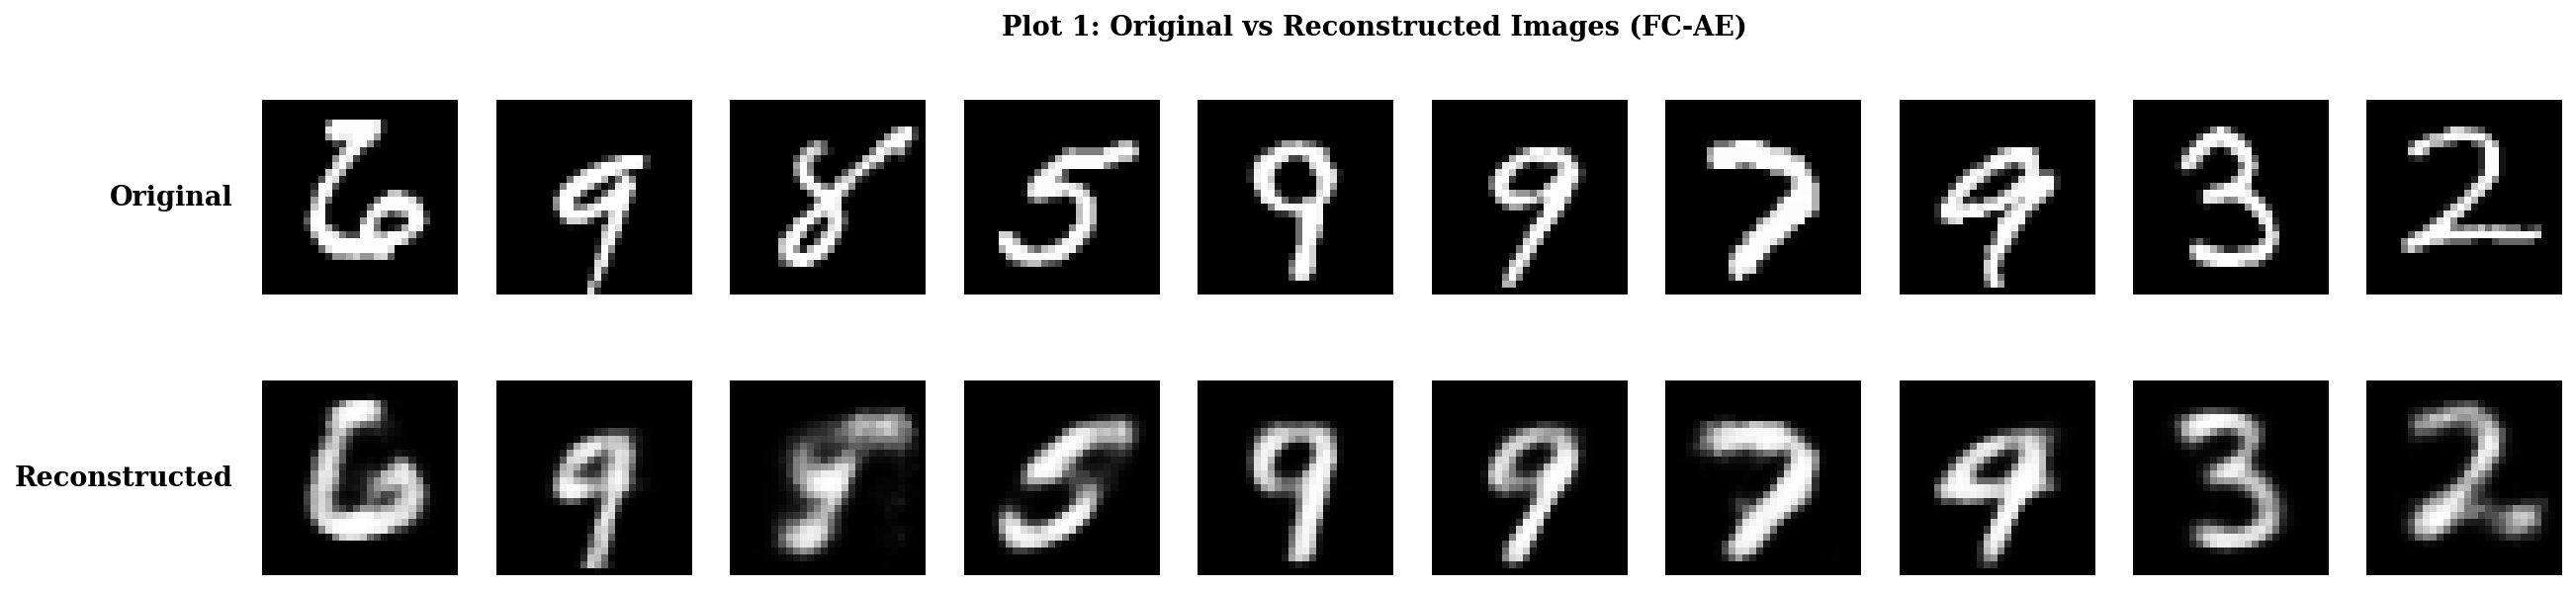

Saved: outputs/figures/plot2_fc_training_validation_loss.png


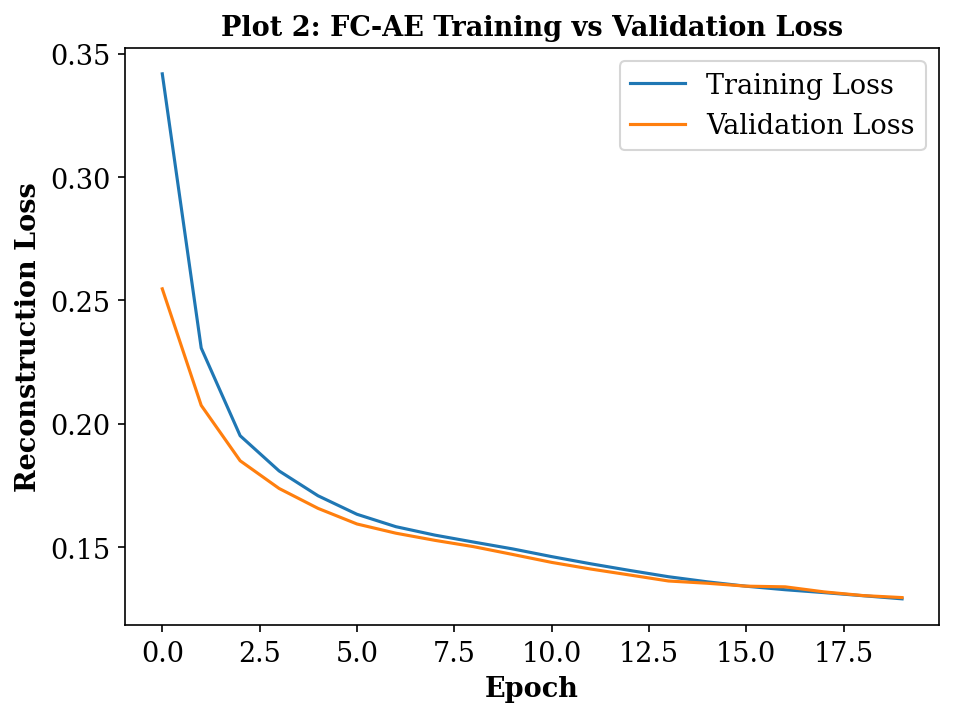

In [5]:
# ---- Plot 1: Original vs Reconstructed Images ----
n_show = 10
fig, axes = plt.subplots(2, n_show, figsize=(20, 4.5))
for i in range(n_show):
    orig = x_test_flat[i].reshape(28, 28)
    recon = fc_recon_test[i].reshape(28, 28)
    axes[0, i].imshow(orig, cmap='gray')
    axes[0, i].axis('off')
    axes[1, i].imshow(recon, cmap='gray')
    axes[1, i].axis('off')
axes[0, 0].text(-0.15, 0.5, "Original", fontsize=13, fontweight='bold', fontfamily='serif',
                 ha='right', va='center', transform=axes[0, 0].transAxes)
axes[1, 0].text(-0.15, 0.5, "Reconstructed", fontsize=13, fontweight='bold', fontfamily='serif',
                 ha='right', va='center', transform=axes[1, 0].transAxes)
fig.suptitle("Plot 1: Original vs Reconstructed Images (FC-AE)", fontsize=13, fontweight='bold', fontfamily='serif')
save_fig(fig, "plot1_fc_original_vs_reconstructed")

# ---- Plot 2: Training and Validation Reconstruction Loss ----
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fc_history.history['loss'], label='Training Loss')
ax.plot(fc_history.history['val_loss'], label='Validation Loss')
bold_axes(ax, "Epoch", "Reconstruction Loss", "Plot 2: FC-AE Training vs Validation Loss")
ax.legend(prop={'family': 'serif', 'size': 13})
save_fig(fig, "plot2_fc_training_validation_loss")

## 3. Reconstruction Metrics — MSE, MAE, SSIM (Section 9)

In [6]:
def compute_metrics(originals, reconstructions):
    """originals, reconstructions: (N, 28, 28) or (N, 784) in [0,1]"""
    orig_flat = originals.reshape(len(originals), -1)
    recon_flat = reconstructions.reshape(len(reconstructions), -1)

    mse = mean_squared_error(orig_flat, recon_flat)
    mae = mean_absolute_error(orig_flat, recon_flat)

    ssim_vals = []
    orig_imgs = originals.reshape(len(originals), 28, 28)
    recon_imgs = reconstructions.reshape(len(reconstructions), 28, 28)
    for o, r in zip(orig_imgs, recon_imgs):
        ssim_vals.append(ssim_metric(o, r, data_range=1.0))
    mean_ssim = float(np.mean(ssim_vals))
    return mse, mae, mean_ssim

fc_mse, fc_mae, fc_ssim = compute_metrics(x_test_flat, fc_recon_test)

fc_metrics_df = pd.DataFrame({
    "Metric": ["Test MSE", "Test MAE", "Mean SSIM"],
    "Value": [fc_mse, fc_mae, fc_ssim]
})
print(fc_metrics_df.to_string(index=False))

   Metric    Value
 Test MSE 0.022250
 Test MAE 0.059545
Mean SSIM 0.748152


## 4. Convolutional Autoencoder — Build and Train (Section 10)

In [7]:
def build_conv_autoencoder():
    inp = Input(shape=(28, 28, 1), name="cae_input")

    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inp)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    encoded = layers.MaxPooling2D(2, padding='same', name="latent_feature_map")(x)

    x = layers.Conv2D(64, 3, activation='relu', padding='same')(encoded)
    x = layers.UpSampling2D(2)(x)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    decoded = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)

    autoencoder = Model(inp, decoded, name="Conv_Autoencoder")
    encoder = Model(inp, encoded, name="Conv_Encoder")

    autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                         loss='binary_crossentropy')
    return autoencoder, encoder

cae_autoencoder, cae_encoder = build_conv_autoencoder()
cae_autoencoder.summary()

cae_history = cae_autoencoder.fit(
    x_train, x_train,
    validation_data=(x_test, x_test),
    epochs=20, batch_size=128, verbose=1
)

cae_recon_test = cae_autoencoder.predict(x_test, verbose=0)
cae_mse, cae_mae, cae_ssim = compute_metrics(x_test, cae_recon_test)
print(f"CAE -> MSE: {cae_mse:.5f}, MAE: {cae_mae:.5f}, SSIM: {cae_ssim:.5f}")

Model: "Conv_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cae_input (InputLayer)          │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_feature_map              │ (None, 7, 7, 64)       │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 49ms/step - loss: 0.2271 - val_loss: 0.1017
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0924 - val_loss: 0.0859
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0845 - val_loss: 0.0812
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0802 - val_loss: 0.0803
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0778 - val_loss: 0.0779
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0761 - val_loss: 0.0774
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0748 - val_loss: 0.0758
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0738 - val_loss: 0.0743
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0729 - val_loss: 0.0720
Epoch 10/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0721 - val_loss: 0.0731
Epoch 11/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0716 - val_loss: 0.0710
Epoch 12/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0711 - val_l

## 5. Comparing Fully Connected and Convolutional Autoencoders (Section 11)

             Model      MSE      MAE     SSIM  Parameters
Fully Connected AE 0.022250 0.059545 0.748152      211040
  Convolutional AE 0.002479 0.015027 0.974972       74497
Saved: outputs/figures/plot3_fc_vs_cae_reconstruction.png


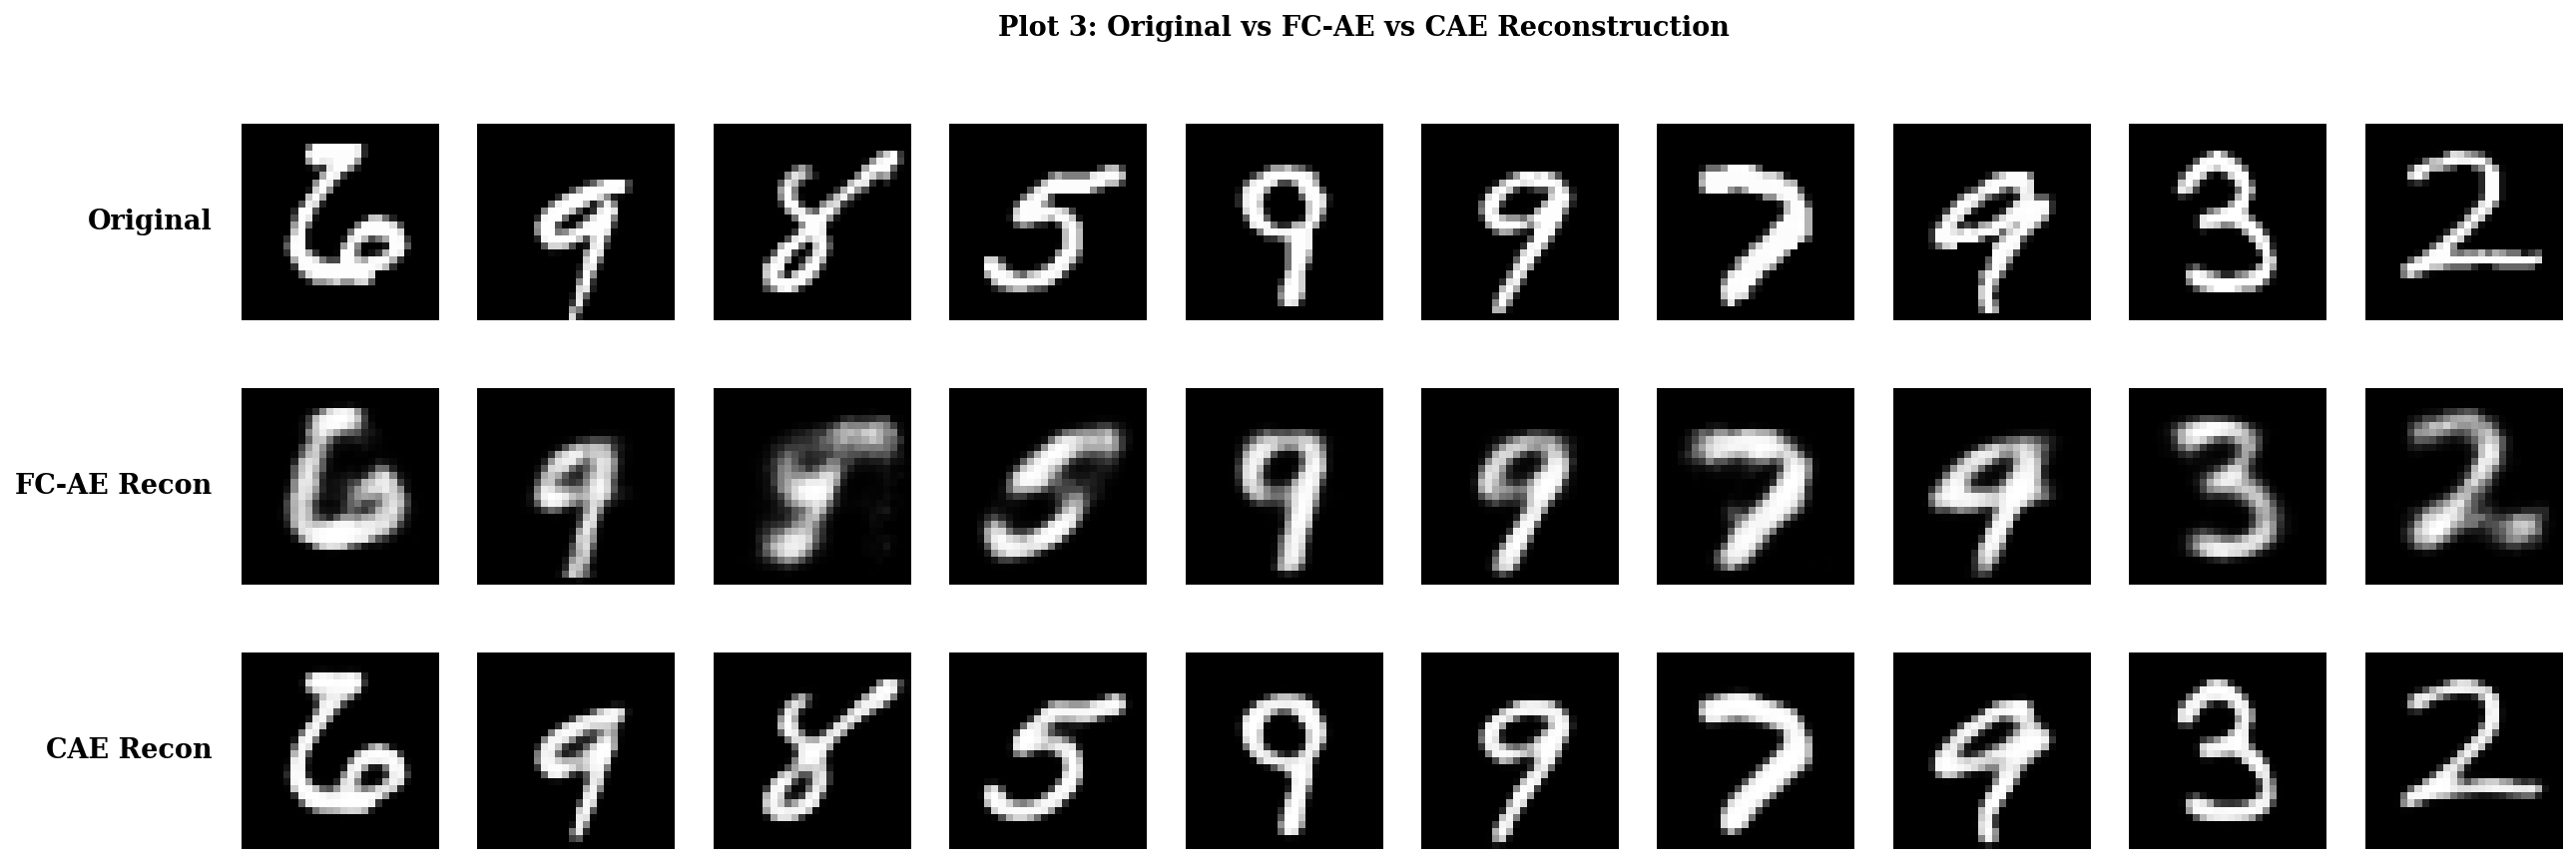

In [8]:
# ---- Comparison table ----
compare_df = pd.DataFrame({
    "Model": ["Fully Connected AE", "Convolutional AE"],
    "MSE": [fc_mse, cae_mse],
    "MAE": [fc_mae, cae_mae],
    "SSIM": [fc_ssim, cae_ssim],
    "Parameters": [fc_autoencoder.count_params(), cae_autoencoder.count_params()]
})
print(compare_df.to_string(index=False))

# ---- Plot 3: Reconstruction Comparison ----
n_show = 10
fig, axes = plt.subplots(3, n_show, figsize=(20, 6.5))
for i in range(n_show):
    orig = x_test[i].reshape(28, 28)
    fc_r = fc_recon_test[i].reshape(28, 28)
    cae_r = cae_recon_test[i].reshape(28, 28)
    axes[0, i].imshow(orig, cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(fc_r, cmap='gray'); axes[1, i].axis('off')
    axes[2, i].imshow(cae_r, cmap='gray'); axes[2, i].axis('off')
axes[0, 0].text(-0.15, 0.5, "Original", fontsize=13, fontweight='bold', fontfamily='serif',
                 ha='right', va='center', transform=axes[0, 0].transAxes)
axes[1, 0].text(-0.15, 0.5, "FC-AE Recon", fontsize=13, fontweight='bold', fontfamily='serif',
                 ha='right', va='center', transform=axes[1, 0].transAxes)
axes[2, 0].text(-0.15, 0.5, "CAE Recon", fontsize=13, fontweight='bold', fontfamily='serif',
                 ha='right', va='center', transform=axes[2, 0].transAxes)
fig.suptitle("Plot 3: Original vs FC-AE vs CAE Reconstruction", fontsize=13, fontweight='bold', fontfamily='serif')
save_fig(fig, "plot3_fc_vs_cae_reconstruction")

## 6. Adding Image Noise — Gaussian and Salt-and-Pepper (Section 13)

In [9]:
def add_gaussian_noise(images, sigma, seed=None):
    rng = np.random.RandomState(seed)
    noisy = images + rng.normal(0, sigma, images.shape).astype('float32')
    return np.clip(noisy, 0.0, 1.0)

def add_salt_pepper_noise(images, p, seed=None):
    rng = np.random.RandomState(seed)
    noisy = images.copy()
    mask = rng.rand(*images.shape)
    noisy[mask < (p / 2)] = 0.0
    noisy[(mask >= (p / 2)) & (mask < p)] = 1.0
    return noisy

# Default training noise: Gaussian sigma=0.2 (mid suggested level)
SIGMA_DEFAULT = 0.2
x_train_noisy = add_gaussian_noise(x_train, SIGMA_DEFAULT, seed=SEED)
x_test_noisy = add_gaussian_noise(x_test, SIGMA_DEFAULT, seed=SEED + 1)

print("Noisy train shape:", x_train_noisy.shape, " range:", x_train_noisy.min(), x_train_noisy.max())

Noisy train shape: (10000, 28, 28, 1)  range: 0.0 1.0


## 7. Denoising Convolutional Autoencoder — Build and Train (Section 12)

In [10]:
def build_denoising_cae():
    return build_conv_autoencoder()  # same architecture as Section 10

denoise_cae, denoise_encoder = build_denoising_cae()

denoise_history = denoise_cae.fit(
    x_train_noisy, x_train,           # noisy input, clean target
    validation_data=(x_test_noisy, x_test),
    epochs=20, batch_size=128, verbose=1
)

denoised_test = denoise_cae.predict(x_test_noisy, verbose=0)
dn_mse, dn_mae, dn_ssim = compute_metrics(x_test, denoised_test)
print(f"Denoising CAE (sigma={SIGMA_DEFAULT}) -> MSE: {dn_mse:.5f}, MAE: {dn_mae:.5f}, SSIM: {dn_ssim:.5f}")

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - loss: 0.2814 - val_loss: 0.1350
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1146 - val_loss: 0.1015
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0962 - val_loss: 0.0930
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0899 - val_loss: 0.0871
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0868 - val_loss: 0.0848
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0847 - val_loss: 0.0831
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0832 - val_loss: 0.0818
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0819 - val_loss: 0.0808
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0810 - val_loss: 0.0799
Epoch 10/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0801 - val_loss: 0.0791
Epoch 11/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0793 - val_loss: 0.0785
Epoch 12/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0787 - val_l

## 8. Required Denoising Plots (Section 14)

Saved: outputs/figures/plot4_clean_noisy_denoised.png


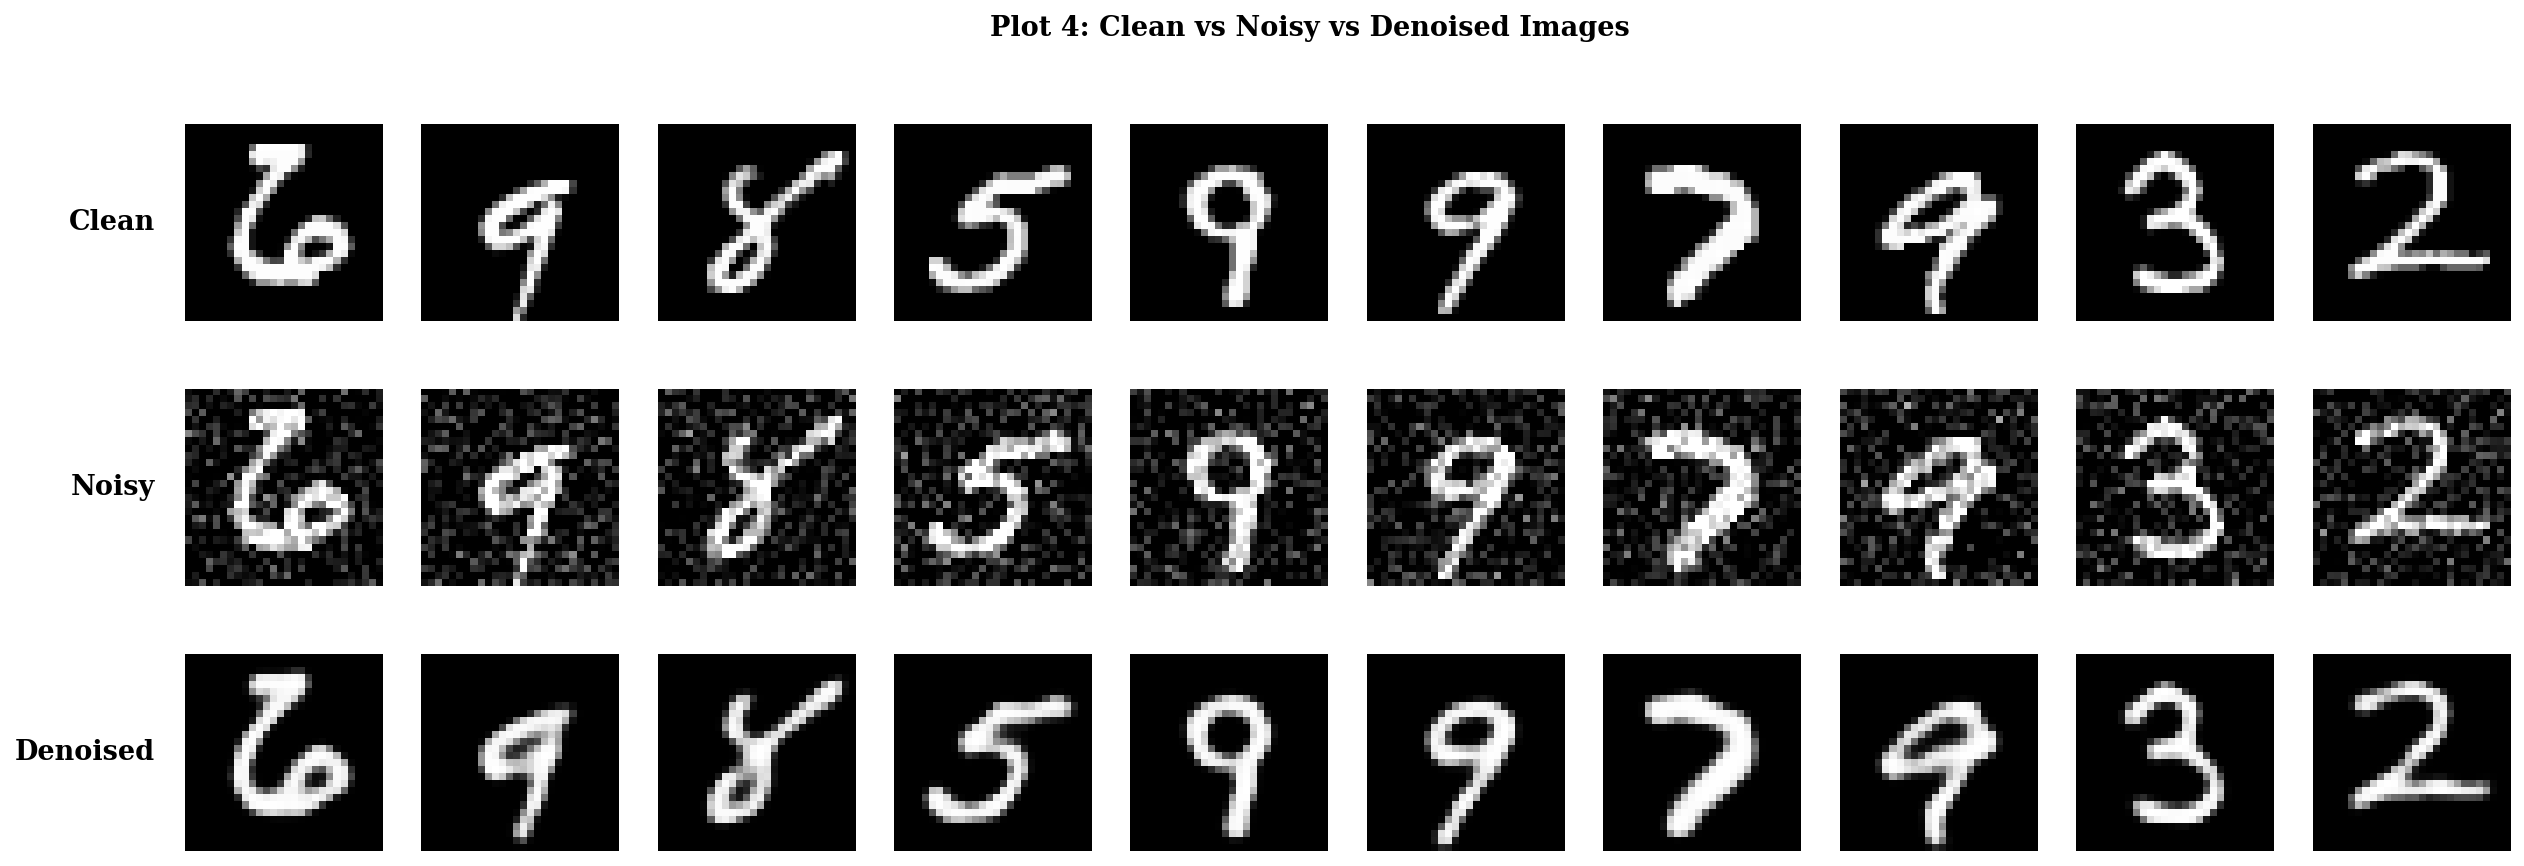

sigma=0.1 -> MSE=0.00304, MAE=0.01686, SSIM=0.96665
sigma=0.2 -> MSE=0.00459, MAE=0.02118, SSIM=0.94732
sigma=0.3 -> MSE=0.00631, MAE=0.02566, SSIM=0.92574
 Noise Level      MSE      MAE     SSIM
         0.1 0.003045 0.016856 0.966647
         0.2 0.004588 0.021180 0.947325
         0.3 0.006309 0.025659 0.925741
Saved: outputs/figures/plot5_noise_level_vs_quality.png


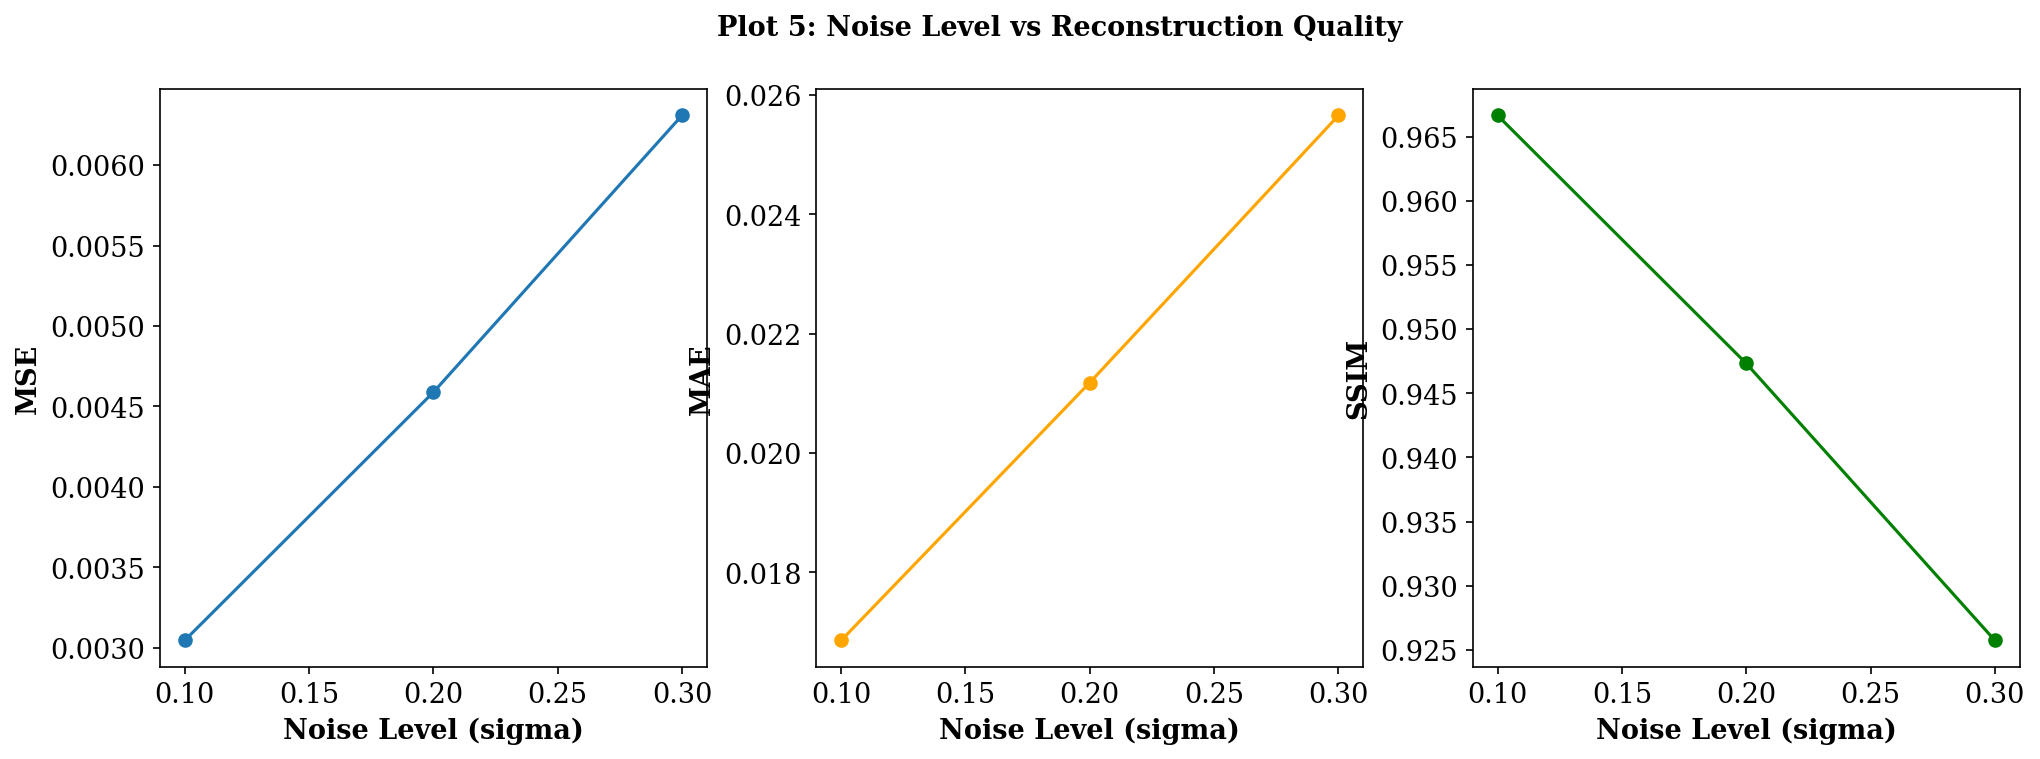

In [11]:
# ---- Plot 4: Clean vs Noisy vs Denoised ----
n_show = 10
fig, axes = plt.subplots(3, n_show, figsize=(20, 6.5))
for i in range(n_show):
    clean = x_test[i].reshape(28, 28)
    noisy = x_test_noisy[i].reshape(28, 28)
    denoised = denoised_test[i].reshape(28, 28)
    axes[0, i].imshow(clean, cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(noisy, cmap='gray'); axes[1, i].axis('off')
    axes[2, i].imshow(denoised, cmap='gray'); axes[2, i].axis('off')
axes[0, 0].text(-0.15, 0.5, "Clean", fontsize=13, fontweight='bold', fontfamily='serif',
                 ha='right', va='center', transform=axes[0, 0].transAxes)
axes[1, 0].text(-0.15, 0.5, "Noisy", fontsize=13, fontweight='bold', fontfamily='serif',
                 ha='right', va='center', transform=axes[1, 0].transAxes)
axes[2, 0].text(-0.15, 0.5, "Denoised", fontsize=13, fontweight='bold', fontfamily='serif',
                 ha='right', va='center', transform=axes[2, 0].transAxes)
fig.suptitle("Plot 4: Clean vs Noisy vs Denoised Images", fontsize=13, fontweight='bold', fontfamily='serif')
save_fig(fig, "plot4_clean_noisy_denoised")

# ---- Plot 5: Noise Level vs Reconstruction Quality ----
sigma_levels = [0.1, 0.2, 0.3]
noise_results = []

for sigma in sigma_levels:
    xtr_n = add_gaussian_noise(x_train, sigma, seed=SEED)
    xte_n = add_gaussian_noise(x_test, sigma, seed=SEED + 1)

    model, _ = build_denoising_cae()
    model.fit(xtr_n, x_train, validation_data=(xte_n, x_test),
              epochs=20, batch_size=128, verbose=0)

    recon = model.predict(xte_n, verbose=0)
    m, a, s = compute_metrics(x_test, recon)
    noise_results.append({"Noise Level": sigma, "MSE": m, "MAE": a, "SSIM": s})
    print(f"sigma={sigma} -> MSE={m:.5f}, MAE={a:.5f}, SSIM={s:.5f}")

noise_level_df = pd.DataFrame(noise_results)
print(noise_level_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].plot(noise_level_df["Noise Level"], noise_level_df["MSE"], marker='o')
bold_axes(axes[0], "Noise Level (sigma)", "MSE")
axes[1].plot(noise_level_df["Noise Level"], noise_level_df["MAE"], marker='o', color='orange')
bold_axes(axes[1], "Noise Level (sigma)", "MAE")
axes[2].plot(noise_level_df["Noise Level"], noise_level_df["SSIM"], marker='o', color='green')
bold_axes(axes[2], "Noise Level (sigma)", "SSIM")
fig.suptitle("Plot 5: Noise Level vs Reconstruction Quality", fontsize=13, fontweight='bold', fontfamily='serif')
save_fig(fig, "plot5_noise_level_vs_quality")

## 9. Additional Exercise — Gaussian vs Salt-and-Pepper Noise Comparison

              Noise Type      MSE      MAE     SSIM
    Gaussian (sigma=0.2) 0.004558 0.021023 0.947821
Salt-and-Pepper (p=0.10) 0.005266 0.022243 0.942448
Saved: outputs/figures/extra_gaussian_vs_saltpepper.png


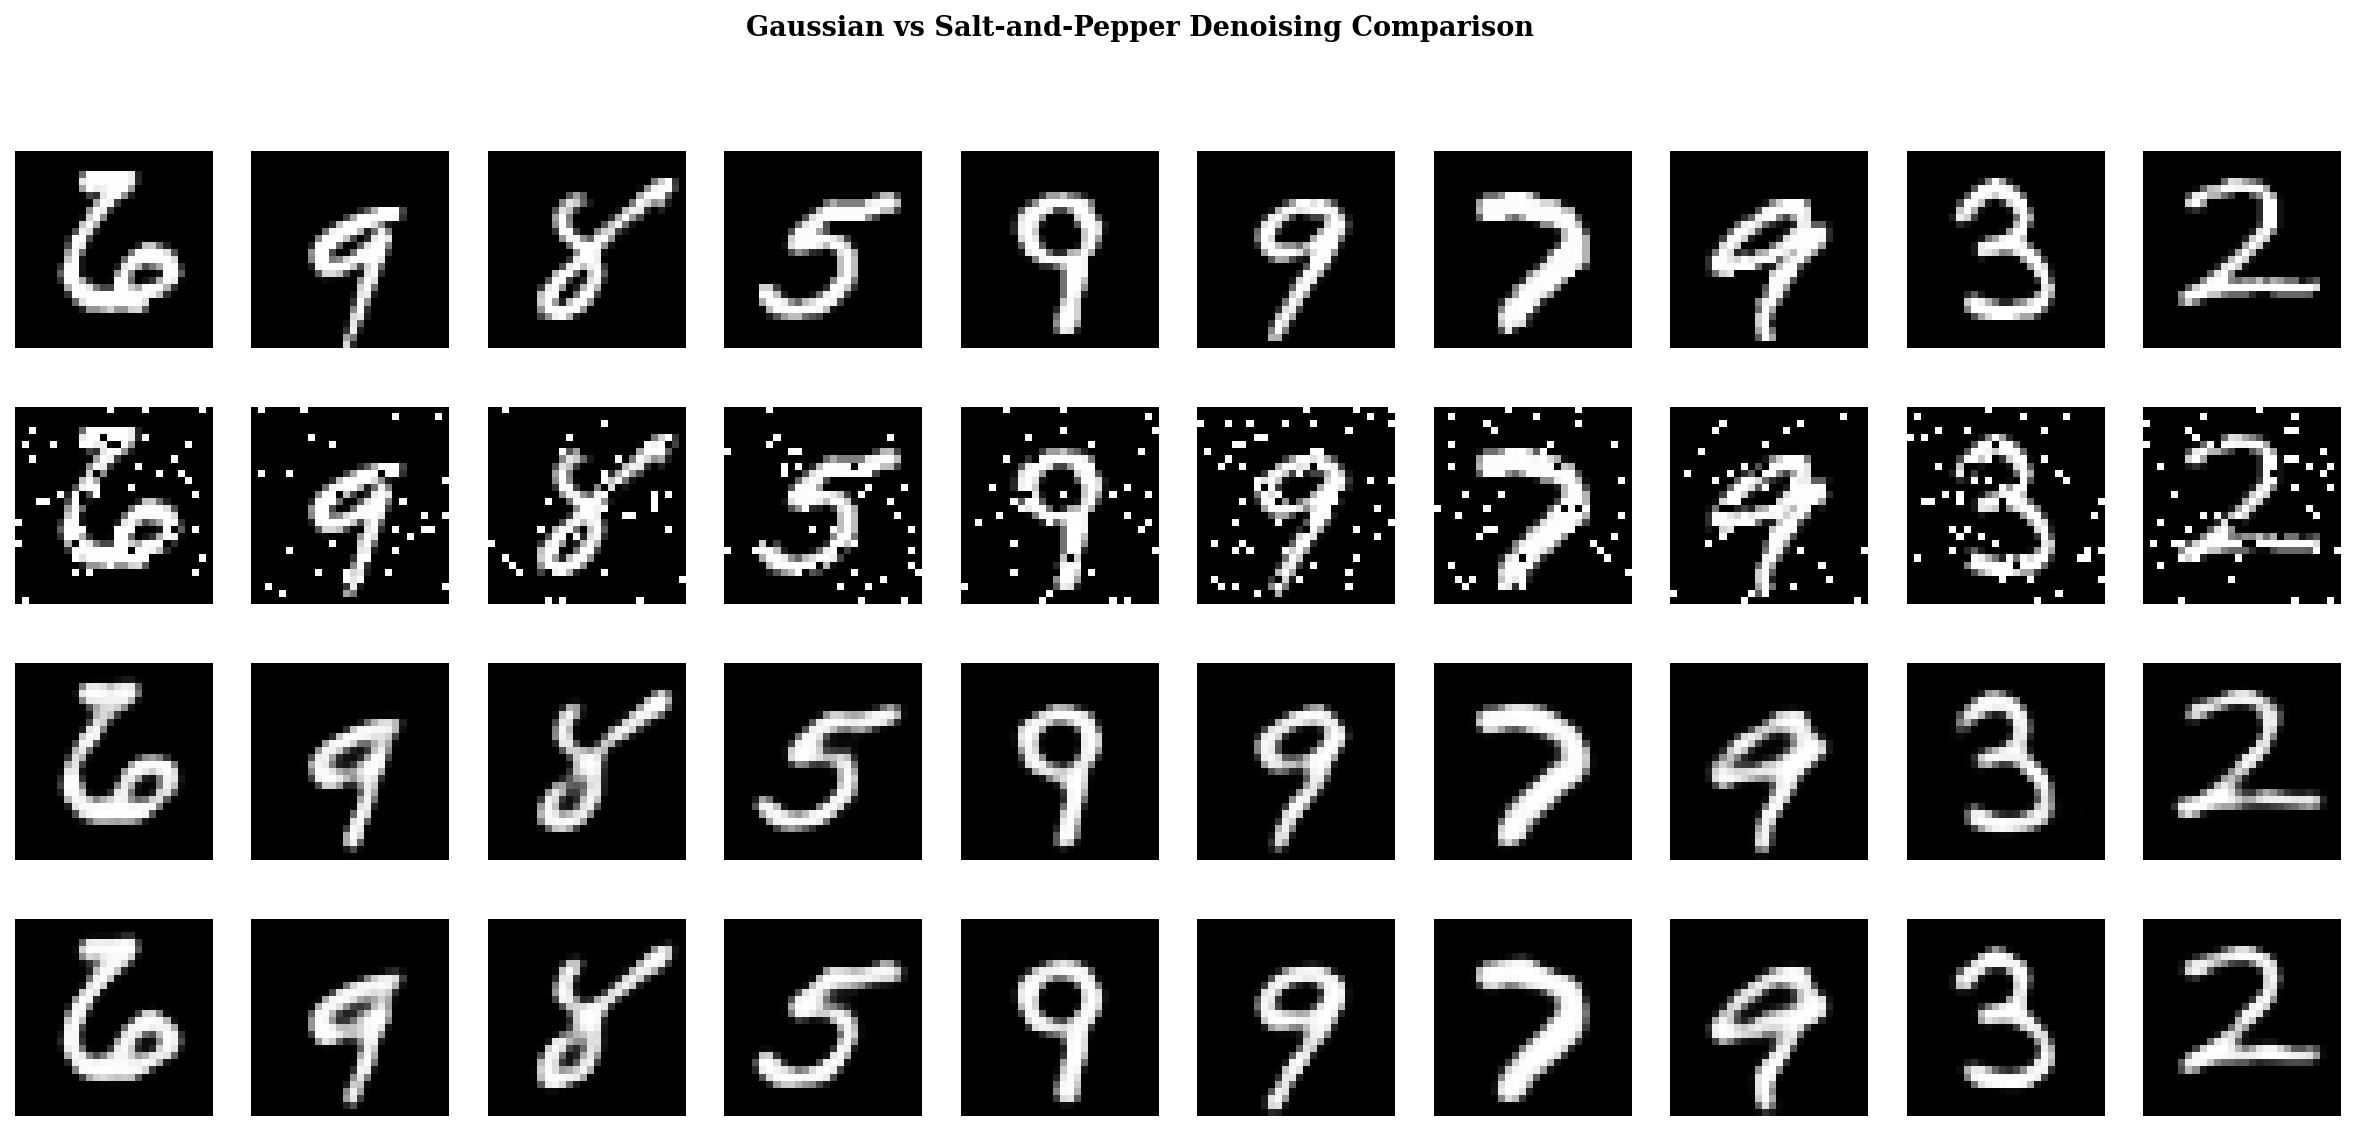

In [12]:
# Compare Gaussian noise (sigma=0.2) vs Salt-and-Pepper noise (p=0.10) using the same architecture
p_default = 0.10
x_train_sp = add_salt_pepper_noise(x_train, p_default, seed=SEED)
x_test_sp = add_salt_pepper_noise(x_test, p_default, seed=SEED + 1)

sp_model, _ = build_denoising_cae()
sp_history = sp_model.fit(
    x_train_sp, x_train,
    validation_data=(x_test_sp, x_test),
    epochs=20, batch_size=128, verbose=0
)
sp_denoised_test = sp_model.predict(x_test_sp, verbose=0)
sp_mse, sp_mae, sp_ssim = compute_metrics(x_test, sp_denoised_test)

noise_type_df = pd.DataFrame({
    "Noise Type": ["Gaussian (sigma=0.2)", "Salt-and-Pepper (p=0.10)"],
    "MSE": [dn_mse, sp_mse],
    "MAE": [dn_mae, sp_mae],
    "SSIM": [dn_ssim, sp_ssim]
})
print(noise_type_df.to_string(index=False))

# Visual comparison
n_show = 10
fig, axes = plt.subplots(4, n_show, figsize=(20, 8.5))
for i in range(n_show):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(x_test_sp[i].reshape(28, 28), cmap='gray'); axes[1, i].axis('off')
    axes[2, i].imshow(sp_denoised_test[i].reshape(28, 28), cmap='gray'); axes[2, i].axis('off')
    axes[3, i].imshow(denoised_test[i].reshape(28, 28), cmap='gray'); axes[3, i].axis('off')
axes[0, 0].set_ylabel("Clean", fontsize=13, fontweight='bold', fontfamily='serif')
axes[1, 0].set_ylabel("S&P Noisy", fontsize=13, fontweight='bold', fontfamily='serif')
axes[2, 0].set_ylabel("S&P Denoised", fontsize=13, fontweight='bold', fontfamily='serif')
axes[3, 0].set_ylabel("Gaussian Denoised", fontsize=13, fontweight='bold', fontfamily='serif')
fig.suptitle("Gaussian vs Salt-and-Pepper Denoising Comparison", fontsize=13, fontweight='bold', fontfamily='serif')
save_fig(fig, "extra_gaussian_vs_saltpepper")

## 10. Variational Autoencoder — Build with Reparameterization Trick (Sections 15–17)

In [13]:
VAE_LATENT_DIM = 2

class Sampling(layers.Layer):
    """Reparameterization trick: z = mu + sigma * epsilon"""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

def build_vae_encoder(latent_dim=2):
    inp = Input(shape=(28, 28, 1), name="vae_input")
    x = layers.Conv2D(32, 3, activation='relu', strides=2, padding='same')(inp)
    x = layers.Conv2D(64, 3, activation='relu', strides=2, padding='same')(x)
    conv_shape = x.shape[1:]  # needed for decoder
    x = layers.Flatten()(x)
    x = layers.Dense(64, activation='relu')(x)
    z_mean = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
    z = Sampling(name="z")([z_mean, z_log_var])
    encoder = Model(inp, [z_mean, z_log_var, z], name="VAE_Encoder")
    return encoder, conv_shape

def build_vae_decoder(latent_dim=2, conv_shape=(7, 7, 64)):
    latent_inp = Input(shape=(latent_dim,), name="z_sampling")
    x = layers.Dense(conv_shape[0] * conv_shape[1] * conv_shape[2], activation='relu')(latent_inp)
    x = layers.Reshape(conv_shape)(x)
    x = layers.Conv2DTranspose(64, 3, activation='relu', strides=2, padding='same')(x)
    x = layers.Conv2DTranspose(32, 3, activation='relu', strides=2, padding='same')(x)
    out = layers.Conv2DTranspose(1, 3, activation='sigmoid', padding='same')(x)
    decoder = Model(latent_inp, out, name="VAE_Decoder")
    return decoder

class VAE(Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.recon_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.recon_loss_tracker, self.kl_loss_tracker]

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        return self.decoder(z)

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)
            recon_loss = tf.reduce_mean(
                tf.reduce_sum(
                    keras.losses.binary_crossentropy(data, reconstruction),
                    axis=(1, 2)
                )
            )
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1)
            )
            total_loss = recon_loss + kl_loss
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {"loss": self.total_loss_tracker.result(),
                "reconstruction_loss": self.recon_loss_tracker.result(),
                "kl_loss": self.kl_loss_tracker.result()}

    def test_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        z_mean, z_log_var, z = self.encoder(data)
        reconstruction = self.decoder(z)
        recon_loss = tf.reduce_mean(
            tf.reduce_sum(keras.losses.binary_crossentropy(data, reconstruction), axis=(1, 2))
        )
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1)
        )
        total_loss = recon_loss + kl_loss
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {"loss": self.total_loss_tracker.result(),
                "reconstruction_loss": self.recon_loss_tracker.result(),
                "kl_loss": self.kl_loss_tracker.result()}

vae_encoder, vae_conv_shape = build_vae_encoder(VAE_LATENT_DIM)
vae_decoder = build_vae_decoder(VAE_LATENT_DIM, vae_conv_shape)
vae = VAE(vae_encoder, vae_decoder)
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3))

vae_encoder.summary()
vae_decoder.summary()

Model: "VAE_Encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ vae_input           │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 14, 14,    │        320 │ vae_input[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 7, 7, 64)  │     18,496 │ conv2d_30[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3136)      │          0 │ conv2d_31[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 64)        │    200,768 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        130 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        130 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Sampling)        │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 219,844 (858.77 KB)

 Trainable params: 219,844 (858.77 KB)

 Non-trainable params: 0 (0.00 B)

Model: "VAE_Decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ z_sampling (InputLayer)         │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3136)           │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,089 (254.25 KB)

 Trainable params: 65,089 (254.25 KB)

 Non-trainable params: 0 (0.00 B)

## 11. VAE Training (Section 16)

In [14]:
vae_epoch_logs = {"loss": [], "val_loss": [], "reconstruction_loss": [], "val_reconstruction_loss": [],
                   "kl_loss": [], "val_kl_loss": []}

EPOCHS_VAE = 20
BATCH_SIZE_VAE = 128

train_ds = tf.data.Dataset.from_tensor_slices(x_train).shuffle(len(x_train)).batch(BATCH_SIZE_VAE)
val_ds = tf.data.Dataset.from_tensor_slices(x_test).batch(BATCH_SIZE_VAE)

for epoch in range(EPOCHS_VAE):
    for tr_metric in vae.metrics:
        tr_metric.reset_state()
    for batch in train_ds:
        vae.train_step(batch)
    train_results = {m.name: float(m.result()) for m in vae.metrics}

    for tr_metric in vae.metrics:
        tr_metric.reset_state()
    for batch in val_ds:
        vae.test_step(batch)
    val_results = {m.name: float(m.result()) for m in vae.metrics}

    vae_epoch_logs["loss"].append(train_results["total_loss"])
    vae_epoch_logs["reconstruction_loss"].append(train_results["reconstruction_loss"])
    vae_epoch_logs["kl_loss"].append(train_results["kl_loss"])
    vae_epoch_logs["val_loss"].append(val_results["total_loss"])
    vae_epoch_logs["val_reconstruction_loss"].append(val_results["reconstruction_loss"])
    vae_epoch_logs["val_kl_loss"].append(val_results["kl_loss"])

    print(f"Epoch {epoch+1}/{EPOCHS_VAE} - loss: {train_results['total_loss']:.4f} "
          f"- recon: {train_results['reconstruction_loss']:.4f} - kl: {train_results['kl_loss']:.4f} "
          f"- val_loss: {val_results['total_loss']:.4f}")

Epoch 1/20 - loss: 288.7676 - recon: 285.9664 - kl: 2.8012 - val_loss: 207.2533
Epoch 2/20 - loss: 197.9816 - recon: 195.2724 - kl: 2.7092 - val_loss: 193.1099
Epoch 3/20 - loss: 186.3493 - recon: 182.6944 - kl: 3.6549 - val_loss: 183.1704
Epoch 4/20 - loss: 181.5927 - recon: 177.5656 - kl: 4.0271 - val_loss: 180.3250
Epoch 5/20 - loss: 179.0173 - recon: 174.9315 - kl: 4.0857 - val_loss: 178.0870
Epoch 6/20 - loss: 177.0291 - recon: 172.8412 - kl: 4.1879 - val_loss: 175.9501
Epoch 7/20 - loss: 174.0733 - recon: 169.7491 - kl: 4.3242 - val_loss: 172.6253
Epoch 8/20 - loss: 170.5826 - recon: 166.0454 - kl: 4.5371 - val_loss: 168.8562
Epoch 9/20 - loss: 167.1156 - recon: 162.3822 - kl: 4.7335 - val_loss: 166.3187
Epoch 10/20 - loss: 165.0476 - recon: 160.1626 - kl: 4.8850 - val_loss: 165.7530
Epoch 11/20 - loss: 163.5991 - recon: 158.6610 - kl: 4.9381 - val_loss: 162.9311
Epoch 12/20 - loss: 161.7581 - recon: 156.7246 - kl: 5.0335 - val_loss: 162.8630
Epoch 13/20 - loss: 160.9404 - recon:

## 12. VAE Training/Validation Loss Curve (Plot 9, Section 22)

Saved: outputs/figures/plot9_vae_training_validation_loss.png


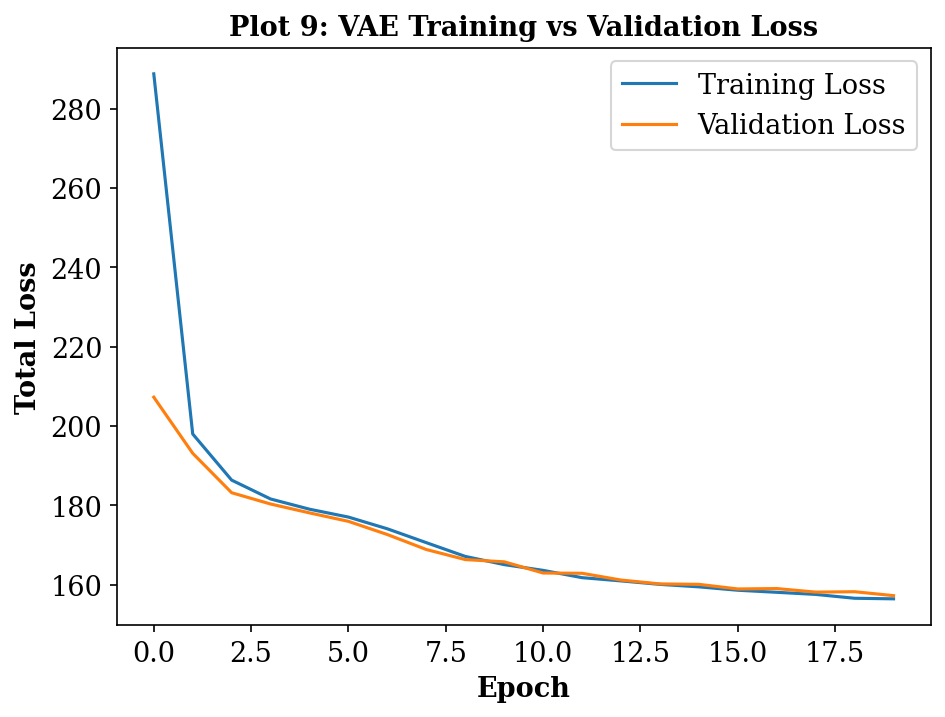

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(vae_epoch_logs["loss"], label="Training Loss")
ax.plot(vae_epoch_logs["val_loss"], label="Validation Loss")
bold_axes(ax, "Epoch", "Total Loss", "Plot 9: VAE Training vs Validation Loss")
ax.legend(prop={'family': 'serif', 'size': 13})
save_fig(fig, "plot9_vae_training_validation_loss")

## 13. Exploring the VAE Latent Space (Plot 6, Section 18)

Saved: outputs/figures/plot6_vae_latent_space.png


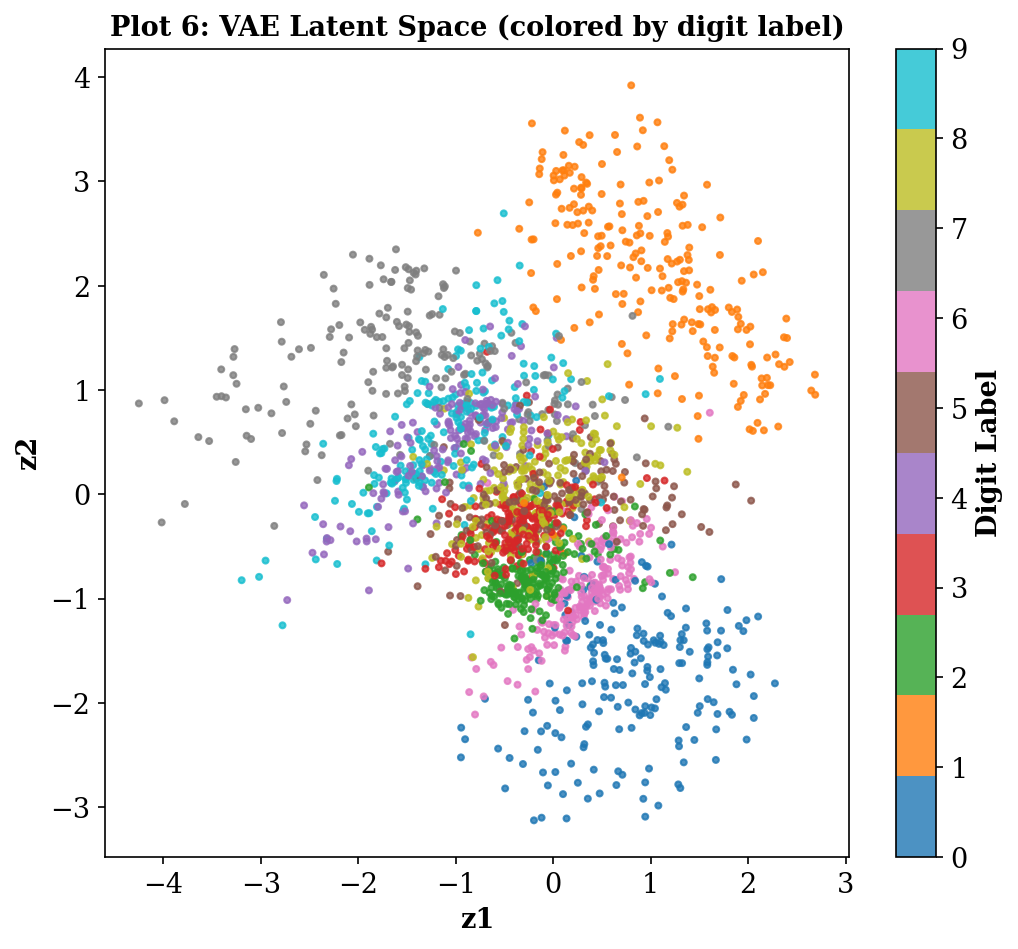

In [16]:
z_mean_test, z_log_var_test, z_test = vae_encoder.predict(x_test, verbose=0)

fig, ax = plt.subplots(figsize=(8, 7))
scatter = ax.scatter(z_mean_test[:, 0], z_mean_test[:, 1], c=y_test, cmap='tab10', s=8, alpha=0.8)
bold_axes(ax, "z1", "z2", "Plot 6: VAE Latent Space (colored by digit label)")
cbar = fig.colorbar(scatter, ax=ax, ticks=range(10))
cbar.set_label("Digit Label", fontsize=13, fontweight='bold', fontfamily='serif')
for t in cbar.ax.get_yticklabels():
    t.set_fontfamily('serif')
save_fig(fig, "plot6_vae_latent_space")

## 14. Generating New Images with the VAE (Plot 7, Section 19)

Saved: outputs/figures/plot7_vae_generated_images.png


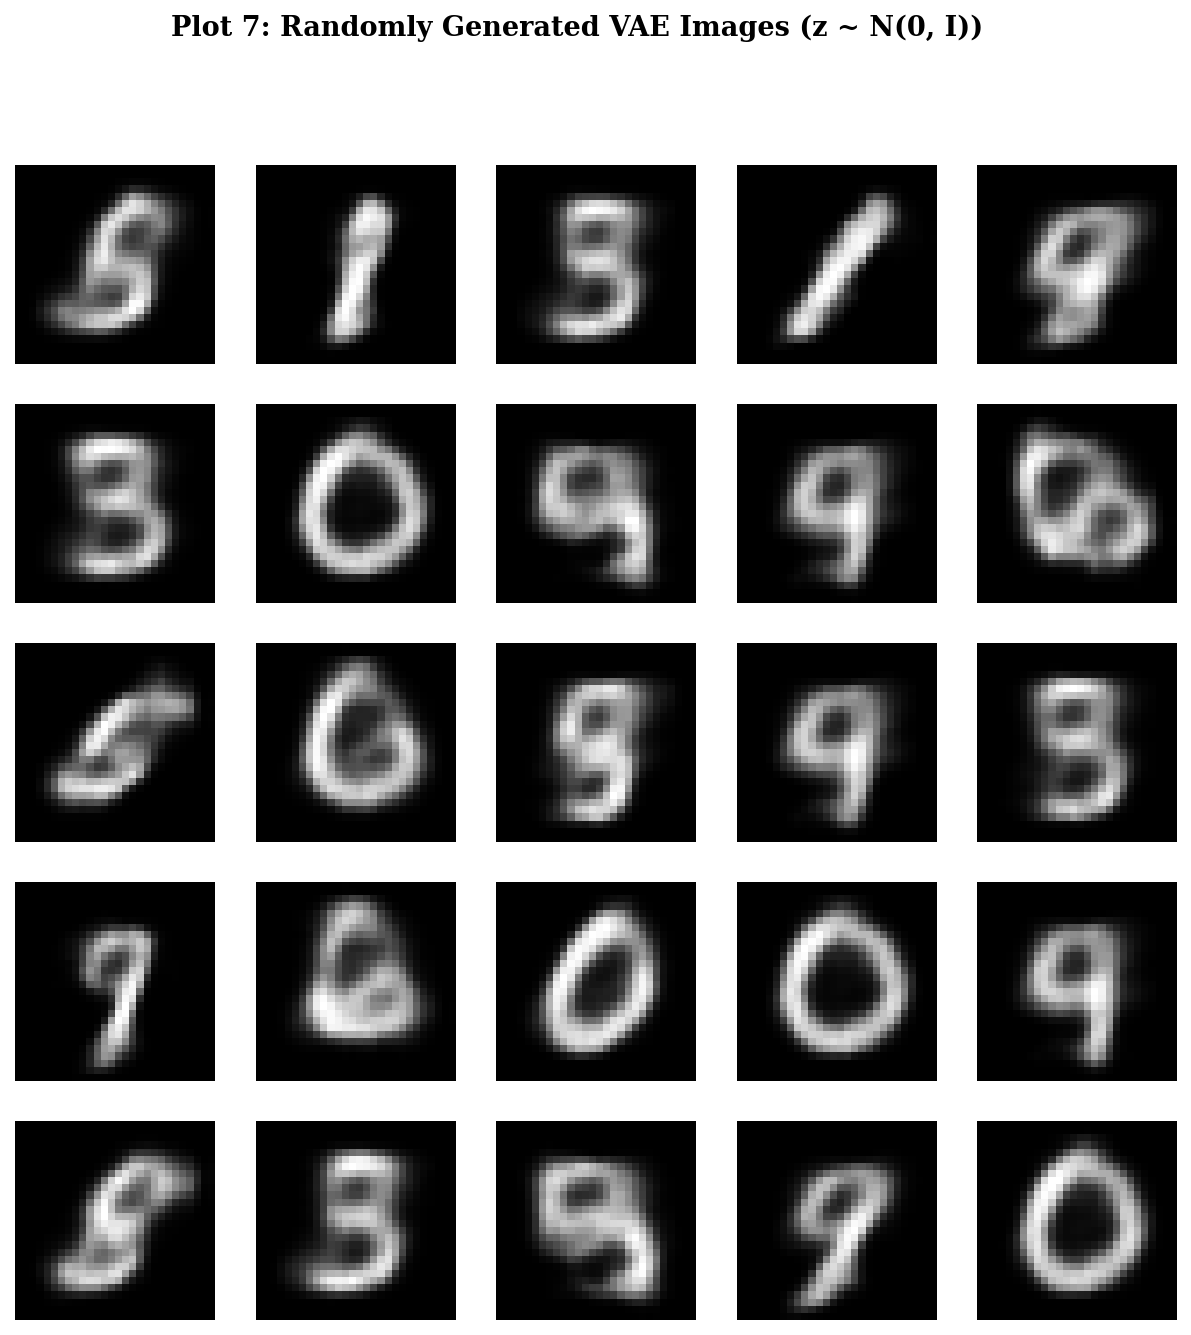

In [17]:
n_gen = 25
rng = np.random.RandomState(SEED)
z_samples = rng.normal(0, 1, size=(n_gen, VAE_LATENT_DIM)).astype('float32')
generated_images = vae_decoder.predict(z_samples, verbose=0)

grid_size = 5
fig, axes = plt.subplots(grid_size, grid_size, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    ax.imshow(generated_images[i].reshape(28, 28), cmap='gray')
    ax.axis('off')
fig.suptitle("Plot 7: Randomly Generated VAE Images (z ~ N(0, I))", fontsize=13, fontweight='bold', fontfamily='serif')
save_fig(fig, "plot7_vae_generated_images")

## 15. Latent Space Interpolation (Plot 8, Section 20)

Saved: outputs/figures/plot8_vae_latent_interpolation.png


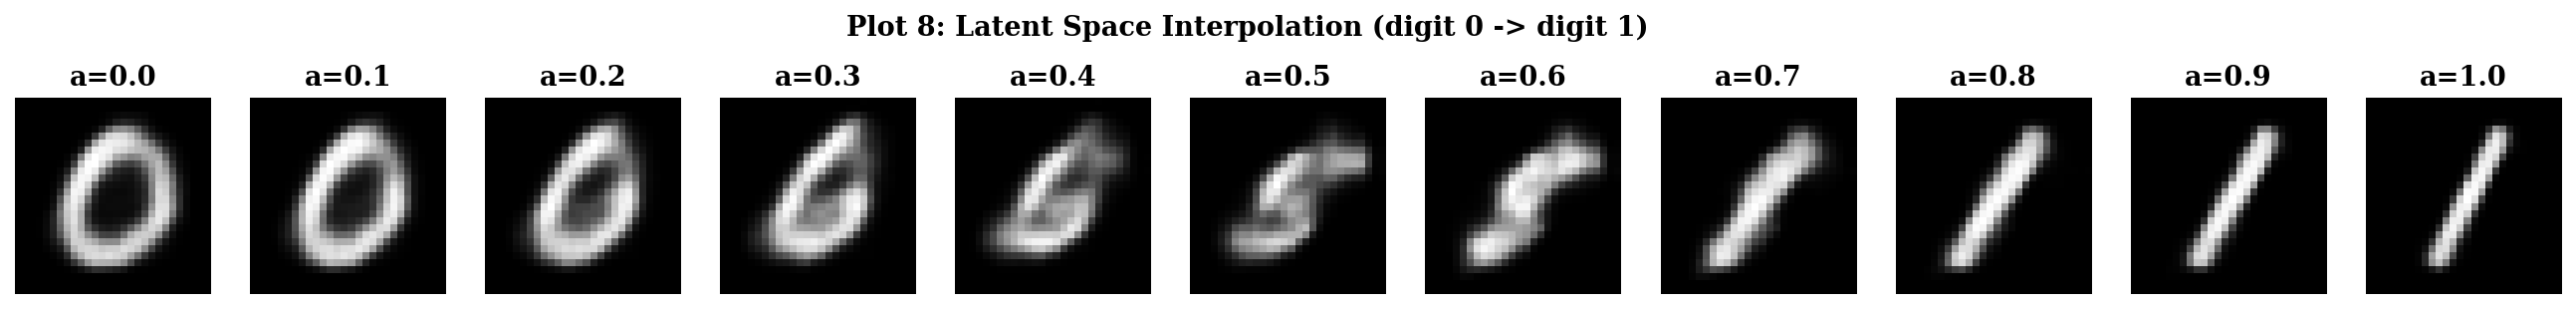

In [18]:
# Select two latent vectors from encoded test images (different digits for clear interpolation)
idx_a = np.where(y_test == 0)[0][0]
idx_b = np.where(y_test == 1)[0][0]

z_A = z_mean_test[idx_a]
z_B = z_mean_test[idx_b]

alphas = np.arange(0, 1.0001, 0.1)
z_interp = np.array([(1 - a) * z_A + a * z_B for a in alphas]).astype('float32')
decoded_interp = vae_decoder.predict(z_interp, verbose=0)

fig, axes = plt.subplots(1, len(alphas), figsize=(2 * len(alphas), 2.5))
for i, ax in enumerate(axes):
    ax.imshow(decoded_interp[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"a={alphas[i]:.1f}", fontsize=13, fontweight='bold', fontfamily='serif')
    ax.axis('off')
fig.suptitle("Plot 8: Latent Space Interpolation (digit 0 -> digit 1)", fontsize=13, fontweight='bold', fontfamily='serif')
save_fig(fig, "plot8_vae_latent_interpolation")

## 16. Reconstruction Comparison Across Models (Section 21)

In [19]:
# VAE reconstruction (mean latent, no sampling noise) for fair comparison
vae_z_mean_test, vae_z_log_var_test, _ = vae_encoder.predict(x_test, verbose=0)
vae_recon_test = vae_decoder.predict(vae_z_mean_test, verbose=0)
vae_mse, vae_mae, vae_ssim = compute_metrics(x_test, vae_recon_test)

# VAE loss components on test set (already computed in vae_epoch_logs for last epoch;
# recompute explicitly here for the report table)
for m in vae.metrics:
    m.reset_state()
for batch in val_ds:
    vae.test_step(batch)
vae_final_test_losses = {m.name: float(m.result()) for m in vae.metrics}

recon_compare_df = pd.DataFrame({
    "Model": ["Fully Connected AE", "Convolutional AE", "Denoising CAE"],
    "MSE": [fc_mse, cae_mse, dn_mse],
    "MAE": [fc_mae, cae_mae, dn_mae],
    "SSIM": [fc_ssim, cae_ssim, dn_ssim],
    "Parameters": [fc_autoencoder.count_params(), cae_autoencoder.count_params(), denoise_cae.count_params()]
})
print(recon_compare_df.to_string(index=False))

vae_metric_df = pd.DataFrame({
    "VAE Metric": ["Reconstruction Loss", "KL Loss", "Total Loss", "Test MSE", "Test MAE", "Mean SSIM"],
    "Value": [vae_final_test_losses["reconstruction_loss"], vae_final_test_losses["kl_loss"],
              vae_final_test_losses["total_loss"], vae_mse, vae_mae, vae_ssim]
})
print(vae_metric_df.to_string(index=False))

             Model      MSE      MAE     SSIM  Parameters
Fully Connected AE 0.022250 0.059545 0.748152      211040
  Convolutional AE 0.002479 0.015027 0.974972       74497
     Denoising CAE 0.004558 0.021023 0.947821       74497
         VAE Metric      Value
Reconstruction Loss 151.665497
            KL Loss   5.489002
         Total Loss 157.154495
           Test MSE   0.044263
           Test MAE   0.102603
          Mean SSIM   0.507384


## 17. Reconstruction Error Distribution (Plot 9 [Sec 23 numbering], Section 23)

Saved: outputs/figures/plot_error_distribution.png


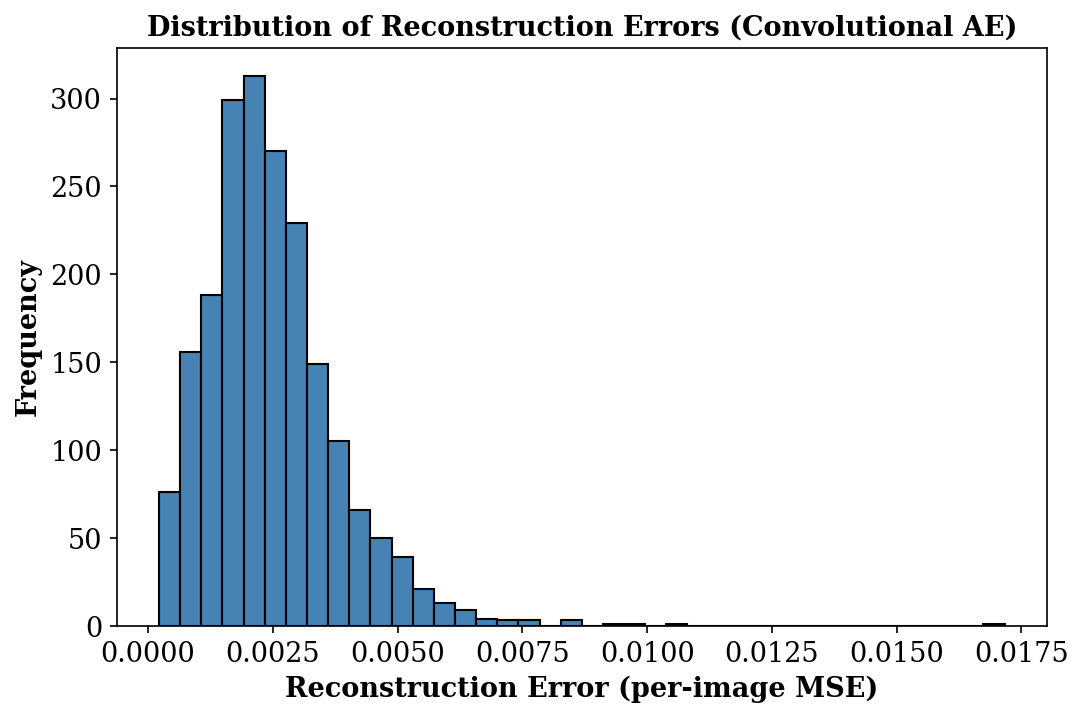

In [20]:
def per_image_error(originals, reconstructions):
    orig_flat = originals.reshape(len(originals), -1)
    recon_flat = reconstructions.reshape(len(reconstructions), -1)
    return np.mean((orig_flat - recon_flat) ** 2, axis=1)

errors_cae = per_image_error(x_test, cae_recon_test)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(errors_cae, bins=40, color='steelblue', edgecolor='black')
bold_axes(ax, "Reconstruction Error (per-image MSE)", "Frequency",
           "Distribution of Reconstruction Errors (Convolutional AE)")
save_fig(fig, "plot_error_distribution")

## 18. Required High-Error Image Analysis (Section 24)

Saved: outputs/figures/plot_high_error_samples.png


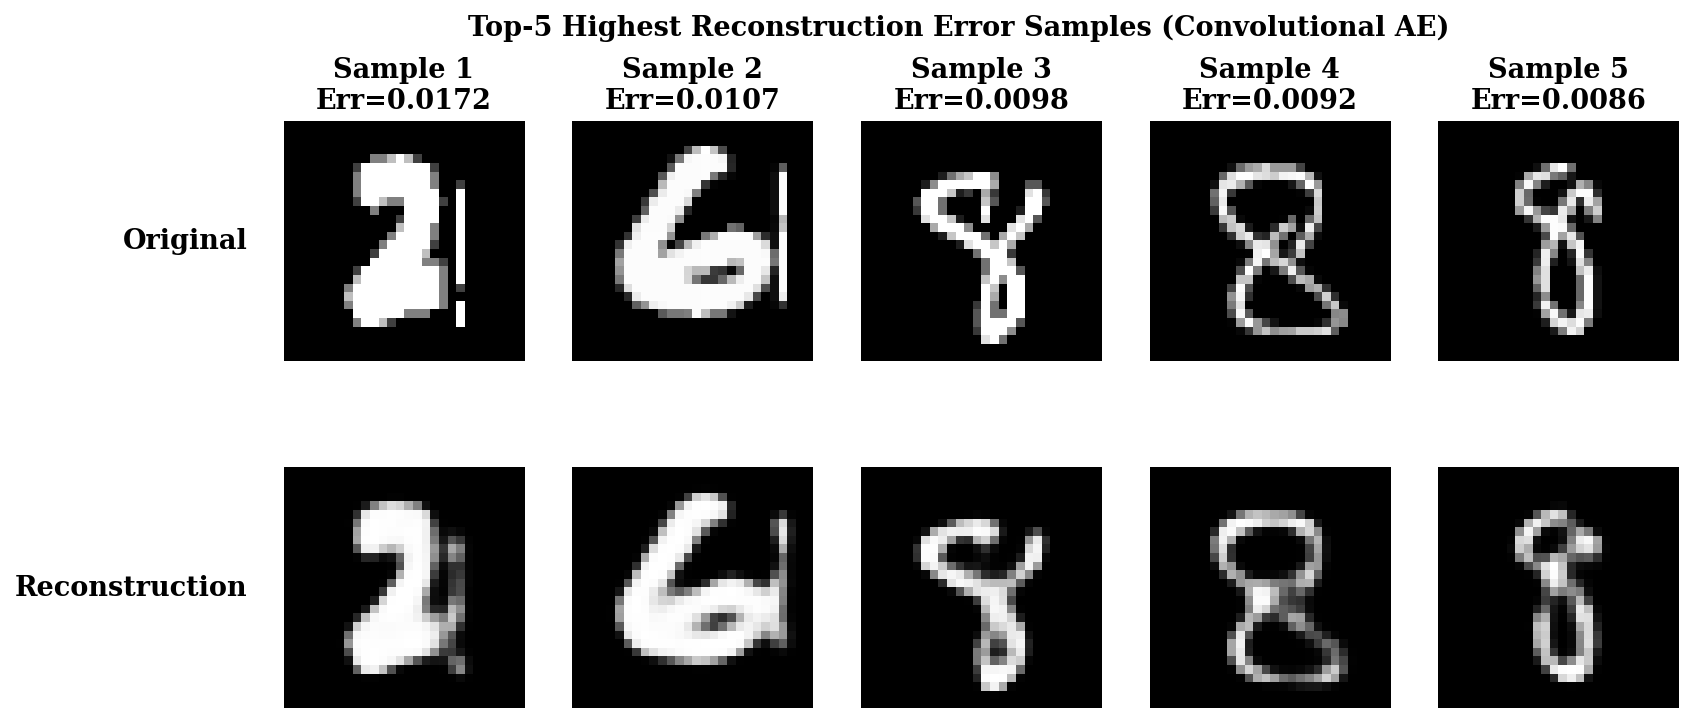

 Sample  Test Index  True Label  Reconstruction Error (MSE)
      1        1670           2                    0.017161
      2          97           6                    0.010745
      3         417           8                    0.009759
      4         262           8                    0.009177
      5        1327           8                    0.008607


In [21]:
top5_idx = np.argsort(errors_cae)[-5:][::-1]

fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for col, idx in enumerate(top5_idx):
    axes[0, col].imshow(x_test[idx].reshape(28, 28), cmap='gray')
    axes[0, col].set_title(f"Sample {col+1}\nErr={errors_cae[idx]:.4f}", fontsize=13, fontweight='bold', fontfamily='serif')
    axes[0, col].axis('off')
    axes[1, col].imshow(cae_recon_test[idx].reshape(28, 28), cmap='gray')
    axes[1, col].axis('off')
axes[0, 0].text(-0.15, 0.5, "Original", fontsize=13, fontweight='bold', fontfamily='serif',
                 ha='right', va='center', transform=axes[0, 0].transAxes)
axes[1, 0].text(-0.15, 0.5, "Reconstruction", fontsize=13, fontweight='bold', fontfamily='serif',
                 ha='right', va='center', transform=axes[1, 0].transAxes)
fig.suptitle("Top-5 Highest Reconstruction Error Samples (Convolutional AE)", fontsize=13, fontweight='bold', fontfamily='serif')
save_fig(fig, "plot_high_error_samples")

high_error_table = pd.DataFrame({
    "Sample": range(1, 6),
    "Test Index": top5_idx,
    "True Label": y_test[top5_idx],
    "Reconstruction Error (MSE)": errors_cae[top5_idx]
})
print(high_error_table.to_string(index=False))

## 19. Consolidated Results Table (Section 25)

In [22]:
def time_training(build_fn, x_in, x_target, x_val_in, x_val_target, epochs=20, batch_size=128):
    model_tuple = build_fn()
    model = model_tuple[0] if isinstance(model_tuple, tuple) else model_tuple
    start = time.time()
    model.fit(x_in, x_target, validation_data=(x_val_in, x_val_target),
              epochs=epochs, batch_size=batch_size, verbose=0)
    elapsed = time.time() - start
    return model, elapsed

# Re-time each model with a fresh instance for a fair "Time" column
_, fc_time = time_training(lambda: build_fc_autoencoder(latent_dim=16),
                            x_train_flat, x_train_flat, x_test_flat, x_test_flat)
_, cae_time = time_training(build_conv_autoencoder, x_train, x_train, x_test, x_test)
_, dn_time = time_training(build_denoising_cae, x_train_noisy, x_train, x_test_noisy, x_test)

vae_start = time.time()
_vae_enc2, _vae_shape2 = build_vae_encoder(VAE_LATENT_DIM)
_vae_dec2 = build_vae_decoder(VAE_LATENT_DIM, _vae_shape2)
_vae2 = VAE(_vae_enc2, _vae_dec2)
_vae2.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3))
_train_ds2 = tf.data.Dataset.from_tensor_slices(x_train).shuffle(len(x_train)).batch(128)
for _ in range(20):
    for batch in _train_ds2:
        _vae2.train_step(batch)
vae_time = time.time() - vae_start

consolidated_df = pd.DataFrame({
    "Model": ["FC Autoencoder", "Conv. Autoencoder", "Denoising CAE", "VAE"],
    "MSE": [fc_mse, cae_mse, dn_mse, vae_mse],
    "MAE": [fc_mae, cae_mae, dn_mae, vae_mae],
    "SSIM": [fc_ssim, cae_ssim, dn_ssim, vae_ssim],
    "Parameters": [fc_autoencoder.count_params(), cae_autoencoder.count_params(),
                    denoise_cae.count_params(), vae_encoder.count_params() + vae_decoder.count_params()],
    "Time (s)": [fc_time, cae_time, dn_time, vae_time]
})
print(consolidated_df.to_string(index=False))

            Model      MSE      MAE     SSIM  Parameters   Time (s)
   FC Autoencoder 0.022250 0.059545 0.748152      211040  11.645111
Conv. Autoencoder 0.002479 0.015027 0.974972       74497  19.189081
    Denoising CAE 0.004558 0.021023 0.947821       74497  19.339031
              VAE 0.044263 0.102603 0.507384      284933 206.552135


## 20. Additional Latent-Dimension Study (Section 27)

latent_dim=2 -> MSE=0.04857, SSIM=0.45992, Params=210130
latent_dim=8 -> MSE=0.02656, SSIM=0.70333, Params=210520
latent_dim=16 -> MSE=0.02435, SSIM=0.72885, Params=211040
latent_dim=32 -> MSE=0.01932, SSIM=0.78047, Params=212080
 Latent Dimension      MSE     SSIM  Parameters
                2 0.048572 0.459916      210130
                8 0.026562 0.703327      210520
               16 0.024345 0.728851      211040
               32 0.019325 0.780466      212080
Saved: outputs/figures/plot10_latent_dimension_vs_mse.png


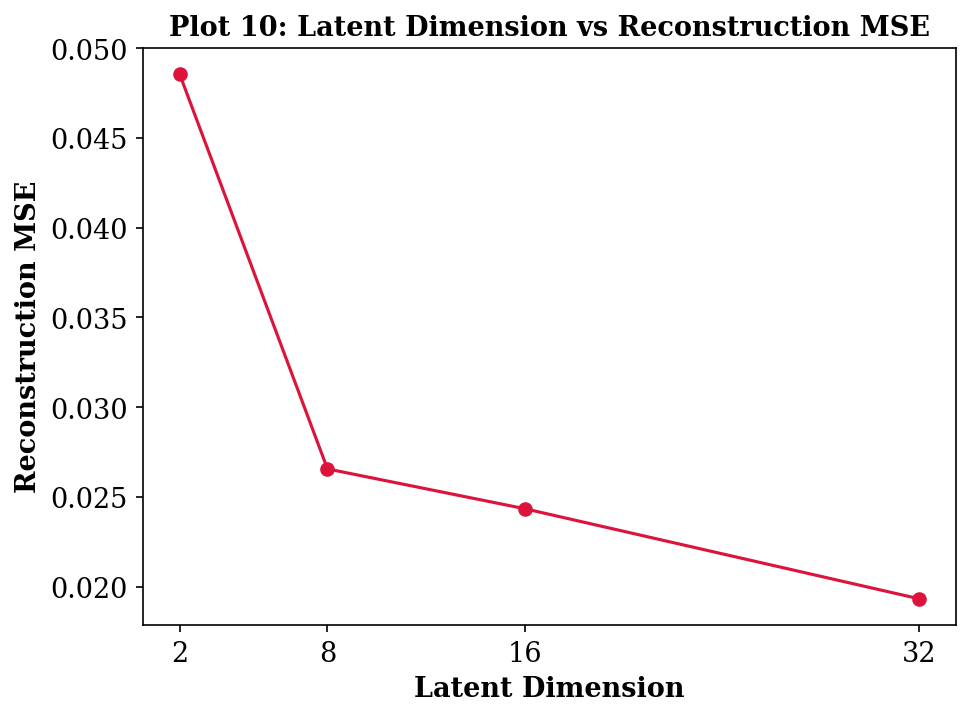

In [23]:
latent_dims = [2, 8, 16, 32]
latent_dim_results = []

for dz in latent_dims:
    model, _ = build_fc_autoencoder(latent_dim=dz)
    model.fit(x_train_flat, x_train_flat, validation_data=(x_test_flat, x_test_flat),
              epochs=20, batch_size=128, verbose=0)
    recon = model.predict(x_test_flat, verbose=0)
    m, a, s = compute_metrics(x_test_flat, recon)
    latent_dim_results.append({"Latent Dimension": dz, "MSE": m, "SSIM": s,
                                "Parameters": model.count_params()})
    print(f"latent_dim={dz} -> MSE={m:.5f}, SSIM={s:.5f}, Params={model.count_params()}")

latent_dim_df = pd.DataFrame(latent_dim_results)
print(latent_dim_df.to_string(index=False))

# ---- Plot 10: Latent Dimension vs Reconstruction MSE ----
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(latent_dim_df["Latent Dimension"], latent_dim_df["MSE"], marker='o', color='crimson')
bold_axes(ax, "Latent Dimension", "Reconstruction MSE", "Plot 10: Latent Dimension vs Reconstruction MSE")
ax.set_xticks(latent_dims)
save_fig(fig, "plot10_latent_dimension_vs_mse")

## 21. Additional Exercise — Convolutional AE with Varying Latent Dimensions

latent_channels=4 -> MSE=0.00856, SSIM=0.91883
latent_channels=8 -> MSE=0.00554, SSIM=0.94481
latent_channels=16 -> MSE=0.00407, SSIM=0.95949
latent_channels=32 -> MSE=0.00316, SSIM=0.96653
 Latent Channels      MSE      MAE     SSIM
               4 0.008560 0.029990 0.918833
               8 0.005544 0.023280 0.944809
              16 0.004067 0.019709 0.959489
              32 0.003157 0.017041 0.966528
Saved: outputs/figures/extra_conv_latent_channels_vs_mse.png


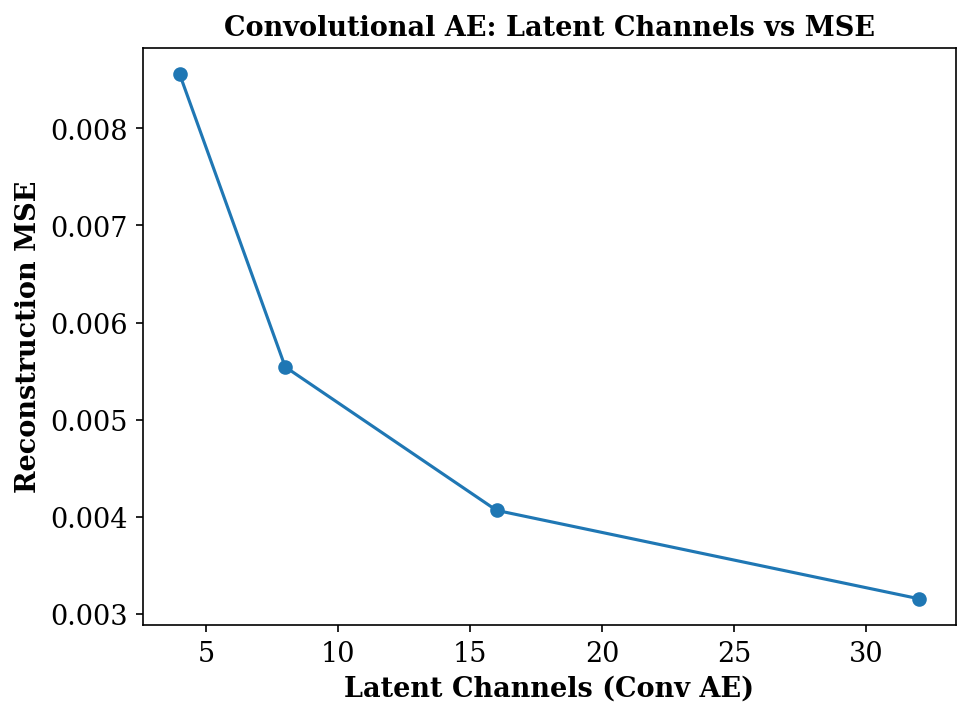

In [24]:
def build_conv_autoencoder_variable_latent(latent_channels=64):
    inp = Input(shape=(28, 28, 1), name="cae_var_input")
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inp)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(latent_channels, 3, activation='relu', padding='same')(x)
    encoded = layers.MaxPooling2D(2, padding='same')(x)

    x = layers.Conv2D(latent_channels, 3, activation='relu', padding='same')(encoded)
    x = layers.UpSampling2D(2)(x)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    decoded = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)

    autoencoder = Model(inp, decoded)
    autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss='binary_crossentropy')
    return autoencoder

conv_latent_channels = [4, 8, 16, 32]
conv_latent_results = []

for lc in conv_latent_channels:
    model = build_conv_autoencoder_variable_latent(latent_channels=lc)
    model.fit(x_train, x_train, validation_data=(x_test, x_test),
              epochs=20, batch_size=128, verbose=0)
    recon = model.predict(x_test, verbose=0)
    m, a, s = compute_metrics(x_test, recon)
    conv_latent_results.append({"Latent Channels": lc, "MSE": m, "MAE": a, "SSIM": s})
    print(f"latent_channels={lc} -> MSE={m:.5f}, SSIM={s:.5f}")

conv_latent_df = pd.DataFrame(conv_latent_results)
print(conv_latent_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(conv_latent_df["Latent Channels"], conv_latent_df["MSE"], marker='o')
bold_axes(ax, "Latent Channels (Conv AE)", "Reconstruction MSE",
           "Convolutional AE: Latent Channels vs MSE")
save_fig(fig, "extra_conv_latent_channels_vs_mse")

## 22. Additional Exercise — Denoising AE at Two Noise Levels (SSIM Comparison)

 Noise Level (sigma)      MSE      MAE     SSIM
                 0.1 0.003051 0.016983 0.965097
                 0.3 0.006585 0.025967 0.921000
Saved: outputs/figures/extra_denoising_ssim_two_levels.png


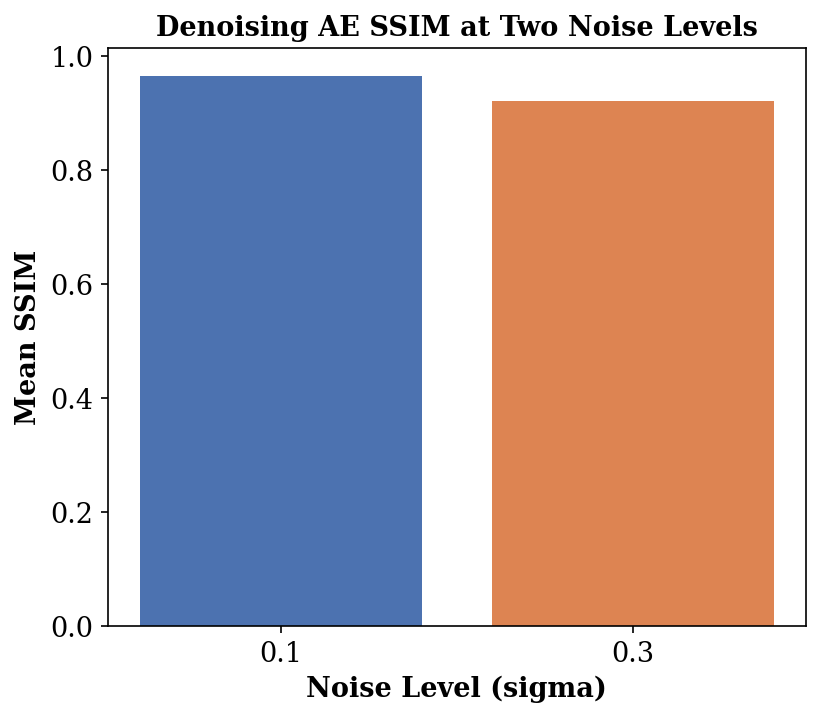

In [25]:
sigma_pair = [0.1, 0.3]
pair_results = []
pair_models = {}

for sigma in sigma_pair:
    xtr_n = add_gaussian_noise(x_train, sigma, seed=SEED)
    xte_n = add_gaussian_noise(x_test, sigma, seed=SEED + 1)
    model, _ = build_denoising_cae()
    model.fit(xtr_n, x_train, validation_data=(xte_n, x_test), epochs=20, batch_size=128, verbose=0)
    recon = model.predict(xte_n, verbose=0)
    m, a, s = compute_metrics(x_test, recon)
    pair_results.append({"Noise Level (sigma)": sigma, "MSE": m, "MAE": a, "SSIM": s})
    pair_models[sigma] = (model, xte_n, recon)

pair_df = pd.DataFrame(pair_results)
print(pair_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 5))
ax.bar([str(s) for s in sigma_pair], pair_df["SSIM"], color=['#4C72B0', '#DD8452'])
bold_axes(ax, "Noise Level (sigma)", "Mean SSIM", "Denoising AE SSIM at Two Noise Levels")
save_fig(fig, "extra_denoising_ssim_two_levels")

## 23. Additional Exercise — Transposed Convolution Decoder vs UpSampling Decoder

   Decoder Type      MSE      MAE     SSIM
   UpSampling2D 0.002479 0.015027 0.974972
Conv2DTranspose 0.002054 0.013458 0.979622
Saved: outputs/figures/extra_upsampling_vs_transpose.png


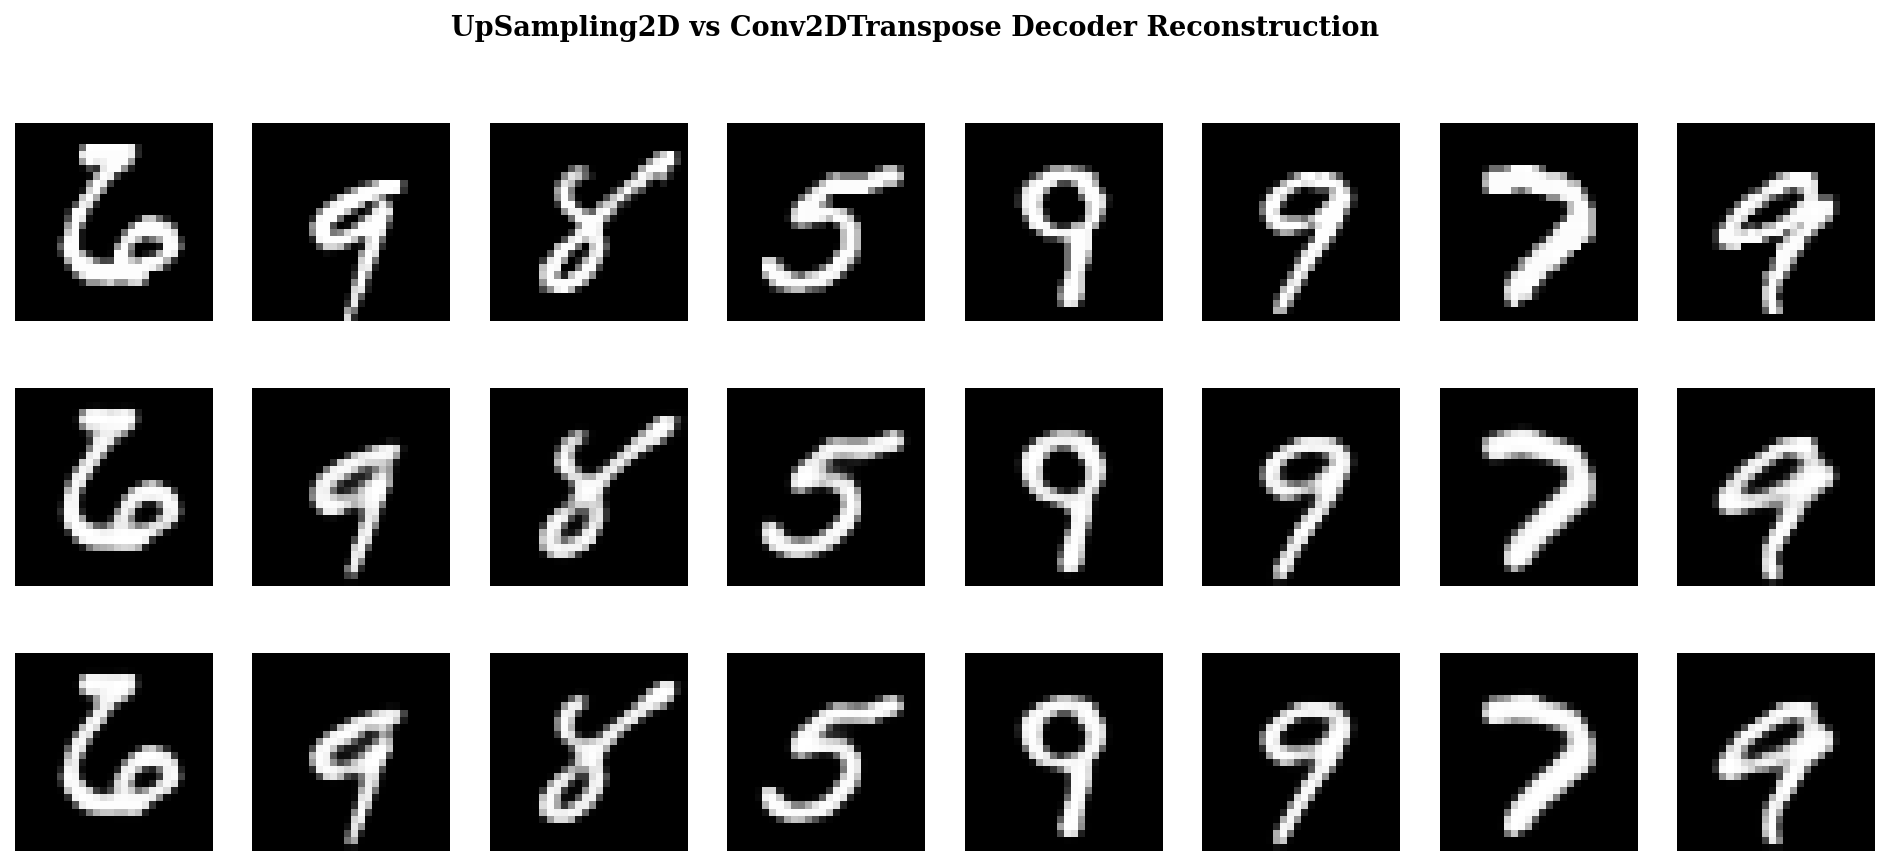

In [26]:
def build_conv_autoencoder_transpose():
    inp = Input(shape=(28, 28, 1), name="cae_t_input")
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inp)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    encoded = layers.MaxPooling2D(2, padding='same')(x)

    x = layers.Conv2DTranspose(64, 3, activation='relu', strides=2, padding='same')(encoded)
    x = layers.Conv2DTranspose(32, 3, activation='relu', strides=2, padding='same')(x)
    decoded = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)

    autoencoder = Model(inp, decoded, name="Conv_Autoencoder_Transpose")
    autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss='binary_crossentropy')
    return autoencoder

cae_transpose = build_conv_autoencoder_transpose()
cae_transpose.fit(x_train, x_train, validation_data=(x_test, x_test),
                   epochs=20, batch_size=128, verbose=0)
transpose_recon_test = cae_transpose.predict(x_test, verbose=0)
t_mse, t_mae, t_ssim = compute_metrics(x_test, transpose_recon_test)

decoder_compare_df = pd.DataFrame({
    "Decoder Type": ["UpSampling2D", "Conv2DTranspose"],
    "MSE": [cae_mse, t_mse],
    "MAE": [cae_mae, t_mae],
    "SSIM": [cae_ssim, t_ssim]
})
print(decoder_compare_df.to_string(index=False))

n_show = 8
fig, axes = plt.subplots(3, n_show, figsize=(16, 6.5))
for i in range(n_show):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(cae_recon_test[i].reshape(28, 28), cmap='gray'); axes[1, i].axis('off')
    axes[2, i].imshow(transpose_recon_test[i].reshape(28, 28), cmap='gray'); axes[2, i].axis('off')
axes[0, 0].set_ylabel("Original", fontsize=13, fontweight='bold', fontfamily='serif')
axes[1, 0].set_ylabel("UpSampling", fontsize=13, fontweight='bold', fontfamily='serif')
axes[2, 0].set_ylabel("Conv2DTranspose", fontsize=13, fontweight='bold', fontfamily='serif')
fig.suptitle("UpSampling2D vs Conv2DTranspose Decoder Reconstruction", fontsize=13, fontweight='bold', fontfamily='serif')
save_fig(fig, "extra_upsampling_vs_transpose")

## 24. Additional Exercise — VAE with Latent Dimension 2 vs 8

 Latent Dimension      MSE      MAE     SSIM
                2 0.044184 0.104597 0.504711
                8 0.019092 0.053513 0.795332
Saved: outputs/figures/extra_vae_latent_dim2_space.png


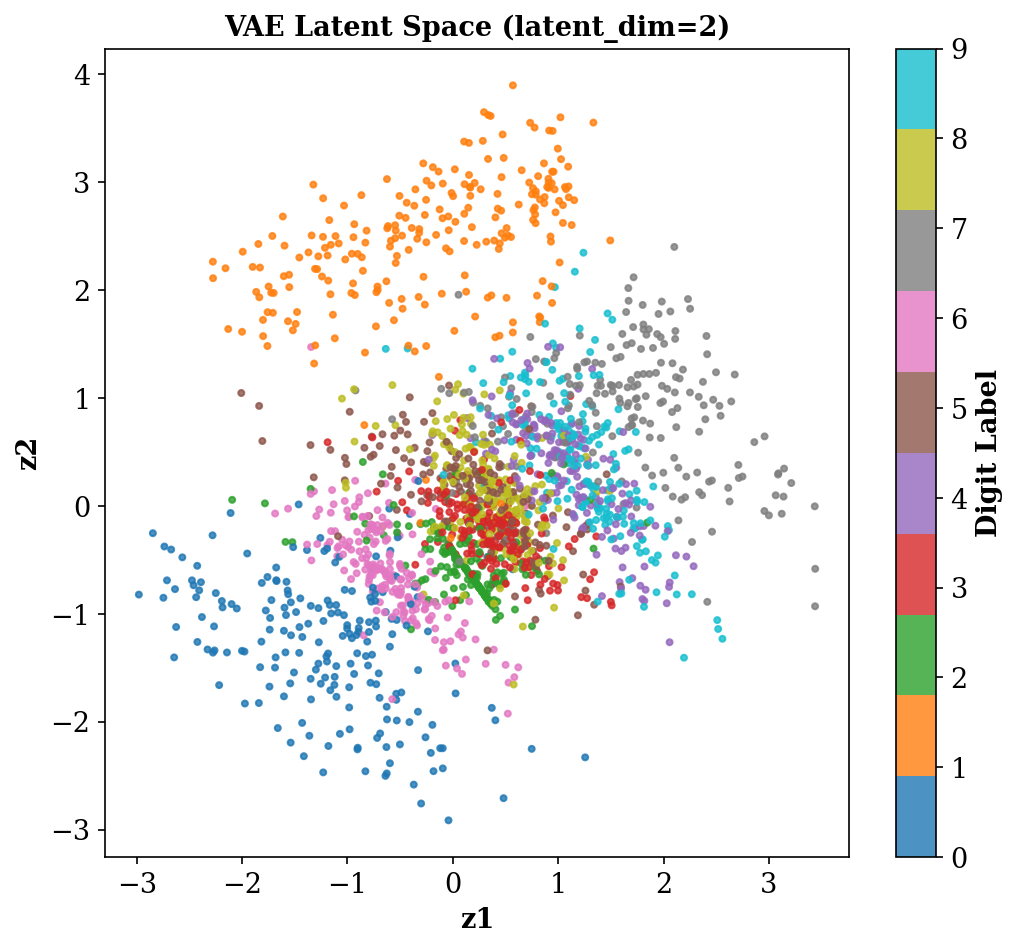

In [27]:
def train_vae(latent_dim, epochs=20, batch_size=128):
    enc, conv_shape = build_vae_encoder(latent_dim)
    dec = build_vae_decoder(latent_dim, conv_shape)
    model = VAE(enc, dec)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3))
    tds = tf.data.Dataset.from_tensor_slices(x_train).shuffle(len(x_train)).batch(batch_size)
    for _ in range(epochs):
        for batch in tds:
            model.train_step(batch)
    return model, enc, dec

vae2_model, vae2_encoder, vae2_decoder = train_vae(2)
vae8_model, vae8_encoder, vae8_decoder = train_vae(8)

z_mean_2, _, _ = vae2_encoder.predict(x_test, verbose=0)
z_mean_8, _, _ = vae8_encoder.predict(x_test, verbose=0)

recon_2 = vae2_decoder.predict(z_mean_2, verbose=0)
recon_8 = vae8_decoder.predict(z_mean_8, verbose=0)
mse2, mae2, ssim2 = compute_metrics(x_test, recon_2)
mse8, mae8, ssim8 = compute_metrics(x_test, recon_8)

vae_dim_compare_df = pd.DataFrame({
    "Latent Dimension": [2, 8],
    "MSE": [mse2, mse8],
    "MAE": [mae2, mae8],
    "SSIM": [ssim2, ssim8]
})
print(vae_dim_compare_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 7))
scatter = ax.scatter(z_mean_2[:, 0], z_mean_2[:, 1], c=y_test, cmap='tab10', s=8, alpha=0.8)
bold_axes(ax, "z1", "z2", "VAE Latent Space (latent_dim=2)")
cbar = fig.colorbar(scatter, ax=ax, ticks=range(10))
cbar.set_label("Digit Label", fontsize=13, fontweight='bold', fontfamily='serif')
save_fig(fig, "extra_vae_latent_dim2_space")

## 25. Additional Exercise — Effect of Increasing KL-Loss Contribution (Beta-VAE)

beta=1.0 -> MSE=0.04505, SSIM=0.50101
beta=5.0 -> MSE=0.04753, SSIM=0.46811
beta=10.0 -> MSE=0.04983, SSIM=0.41841
 Beta      MSE     SSIM
  1.0 0.045055 0.501015
  5.0 0.047528 0.468114
 10.0 0.049827 0.418407
Saved: outputs/figures/extra_beta_vae_ssim.png


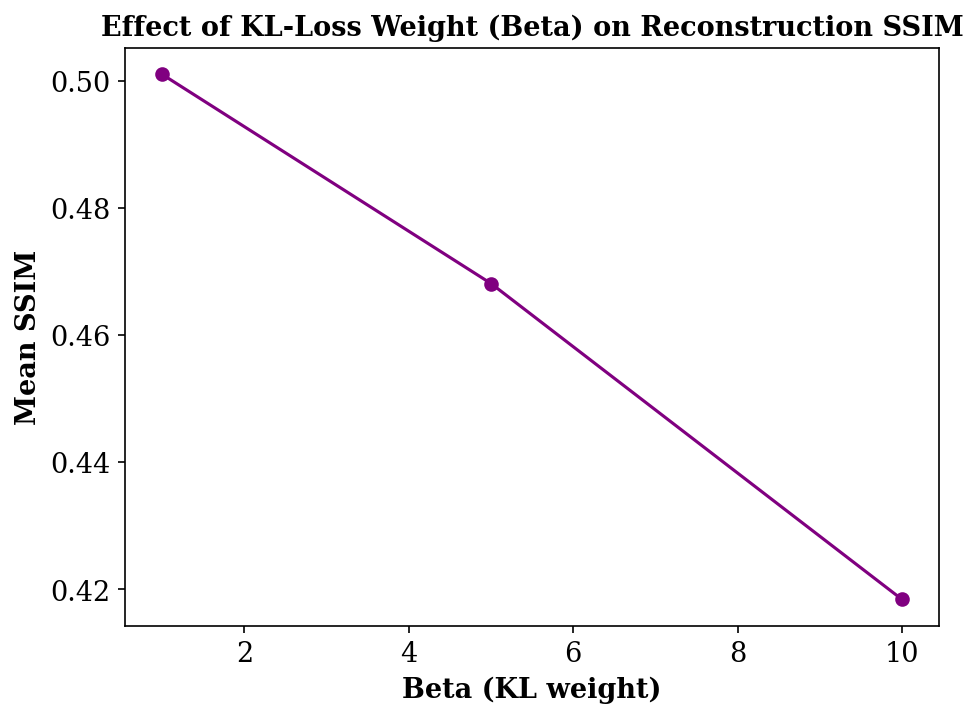

In [28]:
class BetaVAE(VAE):
    def __init__(self, encoder, decoder, beta=1.0, **kwargs):
        super().__init__(encoder, decoder, **kwargs)
        self.beta = beta

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)
            recon_loss = tf.reduce_mean(
                tf.reduce_sum(keras.losses.binary_crossentropy(data, reconstruction), axis=(1, 2))
            )
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1)
            )
            total_loss = recon_loss + self.beta * kl_loss
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {"loss": self.total_loss_tracker.result(),
                "reconstruction_loss": self.recon_loss_tracker.result(),
                "kl_loss": self.kl_loss_tracker.result()}

beta_values = [1.0, 5.0, 10.0]
beta_results = []

for beta in beta_values:
    enc, conv_shape = build_vae_encoder(VAE_LATENT_DIM)
    dec = build_vae_decoder(VAE_LATENT_DIM, conv_shape)
    bvae = BetaVAE(enc, dec, beta=beta)
    bvae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3))
    tds = tf.data.Dataset.from_tensor_slices(x_train).shuffle(len(x_train)).batch(128)
    for _ in range(20):
        for batch in tds:
            bvae.train_step(batch)
    z_mean_b, _, _ = enc.predict(x_test, verbose=0)
    recon_b = dec.predict(z_mean_b, verbose=0)
    m, a, s = compute_metrics(x_test, recon_b)
    beta_results.append({"Beta": beta, "MSE": m, "SSIM": s})
    print(f"beta={beta} -> MSE={m:.5f}, SSIM={s:.5f}")

beta_df = pd.DataFrame(beta_results)
print(beta_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(beta_df["Beta"], beta_df["SSIM"], marker='o', color='purple')
bold_axes(ax, "Beta (KL weight)", "Mean SSIM", "Effect of KL-Loss Weight (Beta) on Reconstruction SSIM")
save_fig(fig, "extra_beta_vae_ssim")

## 26. Additional Exercise — Larger Grid of VAE Samples (Diversity)

Saved: outputs/figures/extra_vae_large_sample_grid.png


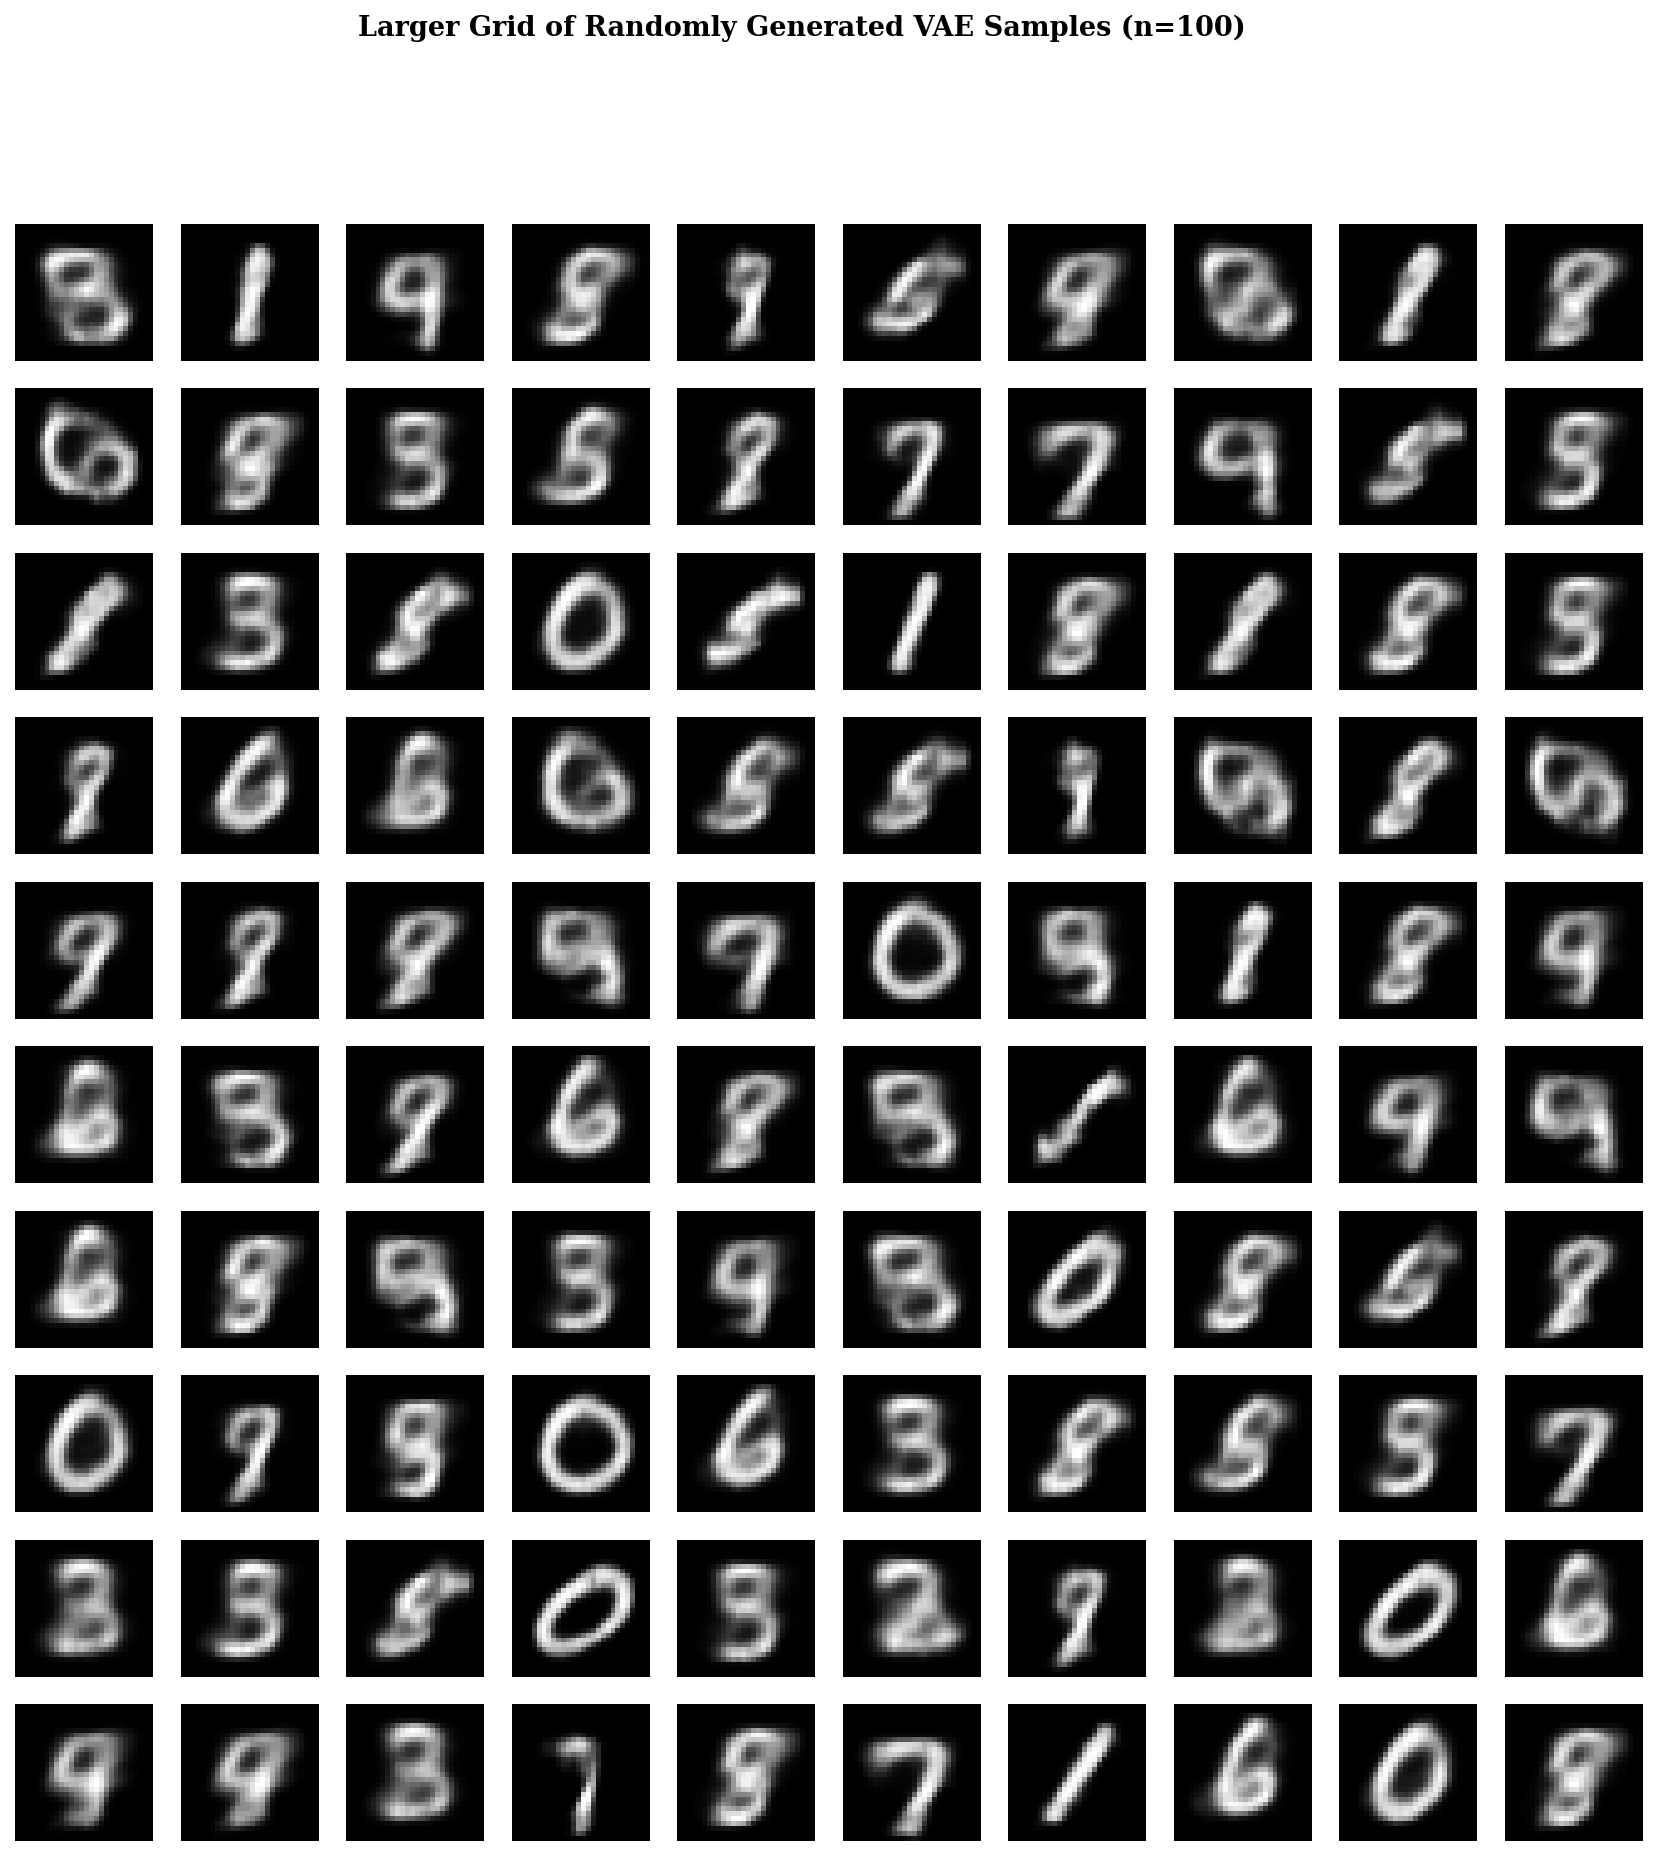

In [29]:
n_gen_large = 100
rng2 = np.random.RandomState(SEED + 7)
z_large = rng2.normal(0, 1, size=(n_gen_large, VAE_LATENT_DIM)).astype('float32')
generated_large = vae_decoder.predict(z_large, verbose=0)

grid_n = 10
fig, axes = plt.subplots(grid_n, grid_n, figsize=(14, 14))
for i, ax in enumerate(axes.flat):
    ax.imshow(generated_large[i].reshape(28, 28), cmap='gray')
    ax.axis('off')
fig.suptitle("Larger Grid of Randomly Generated VAE Samples (n=100)", fontsize=13, fontweight='bold', fontfamily='serif')
save_fig(fig, "extra_vae_large_sample_grid")

## 27. Additional Exercise — Interpolation Between Two Selected Digit Regions

Saved: outputs/figures/extra_interpolation_digit3_to_8.png


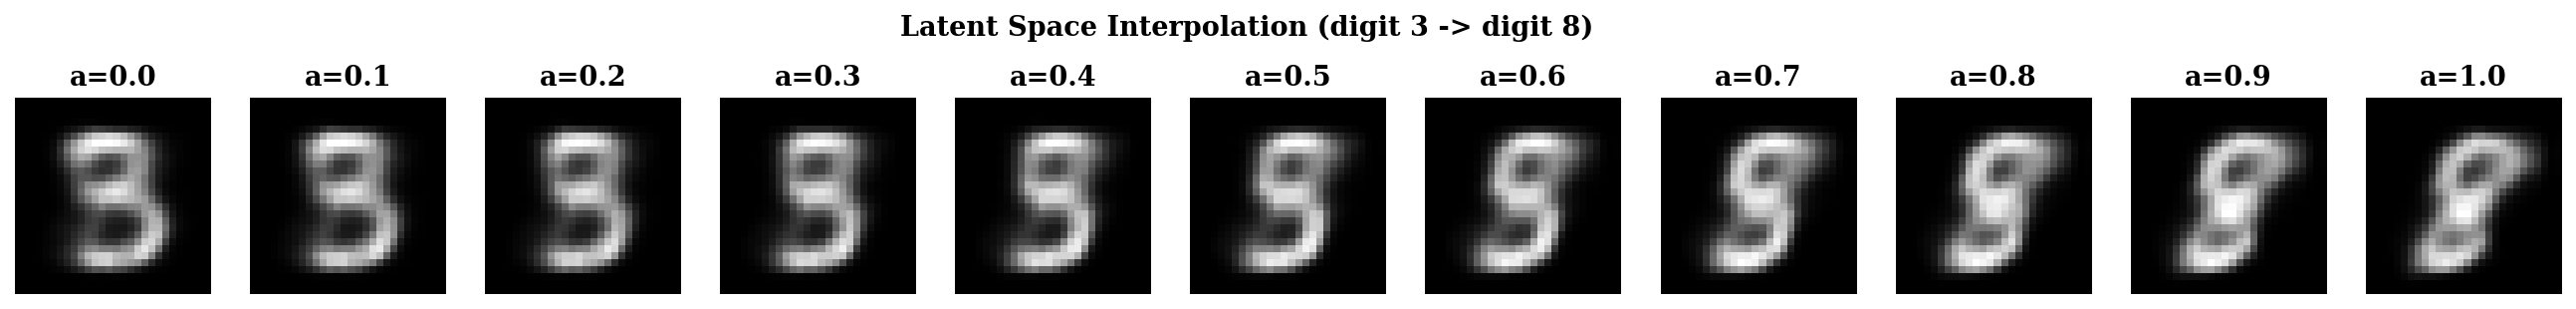

In [30]:
# Select two different digit-region latent vectors (e.g., digit 3 and digit 8)
idx_c = np.where(y_test == 3)[0][0]
idx_d = np.where(y_test == 8)[0][0]

z_C = z_mean_test[idx_c]
z_D = z_mean_test[idx_d]

alphas2 = np.arange(0, 1.0001, 0.1)
z_interp2 = np.array([(1 - a) * z_C + a * z_D for a in alphas2]).astype('float32')
decoded_interp2 = vae_decoder.predict(z_interp2, verbose=0)

fig, axes = plt.subplots(1, len(alphas2), figsize=(2 * len(alphas2), 2.5))
for i, ax in enumerate(axes):
    ax.imshow(decoded_interp2[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"a={alphas2[i]:.1f}", fontsize=13, fontweight='bold', fontfamily='serif')
    ax.axis('off')
fig.suptitle("Latent Space Interpolation (digit 3 -> digit 8)", fontsize=13, fontweight='bold', fontfamily='serif')
save_fig(fig, "extra_interpolation_digit3_to_8")

In [31]:
import shutil
zip_path = shutil.make_archive("outputs/figures_zip", 'zip', "outputs/figures")
print(f"Saved: {zip_path}")

Saved: /kaggle/working/outputs/figures_zip.zip
